# GAINER v3.1 — depth allocation as multi-fidelity value of computation

This notebook adds the **v3.1** contribution on top of the completed v3 run. It reads the cached v3 data (BM25 pools and model trajectories) from Google Drive and writes only to a new `v3_1/` folder, so the v3 results stay untouched.

**Idea.** Each layer block of a cross-encoder is a cheaper, noisier *measurement* of a candidate's final score. Exit heads now also predict their own uncertainty. For every candidate, the allocator computes the **value of computation (VOC)**: how much the expected quality of the top-10 ranking would improve if it spent the next block (or all remaining blocks) on that candidate, per layer of cost. It then spends the budget where that value is highest.

* **Label-free:** VOC needs no relevance judgments. Its target is agreement with the reranker's own full-depth ranking.
* **Comparable across queries:** values are in normalized DCG units, so one budget can be shared by a batch of queries (the v3 pooling test failed because learned pairwise scores are not comparable across queries).
* **GAINER+VOC:** the learned v3 controller gets the VOC terms as extra inputs.

**Pre-registered hypotheses (section 2):** H4 VOC > Current Rank · H5 pooled VOC > per-query VOC · H6 GAINER+VOC > GAINER.

**Requirements:** the v3 notebook must have run to completion on this Drive (it provides the cache). Runtime: GPU. Expected time: about 2–3 h for both backbones and 5 seeds on an L4/A100-class GPU (faster on the Blackwell GPU you used for v3). Set `QUICK_TRIAL = True` for a short check first.

## 0. Install (same pins as v3)

In [ ]:
%pip -q install "transformers==5.18.0" "sentence-transformers==6.1.0" "bm25s[core]==0.3.12" "PyStemmer==3.1.0" "pytrec_eval-terrier==0.5.10" pyarrow jinja2

## 1. Configuration

In [ ]:
from __future__ import annotations

import gc
import hashlib
import json
import math
import os
import platform
import random
import time
from dataclasses import dataclass
from datetime import datetime, timezone
from pathlib import Path
from typing import Callable, Dict, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

import transformers
import sentence_transformers

SMOKE = os.environ.get("GAINER_SMOKE_TEST") == "1"   # offline test hook; leave unset on Colab
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
for _mod, _want in [(transformers, "5.18.0"), (sentence_transformers, "6.1.0")]:
    if _mod.__version__ != _want:
        print(f"WARNING: {_mod.__name__} {_mod.__version__} loaded, {_want} pinned. Restart the session after installing.")

QUICK_TRIAL = False

USE_GOOGLE_DRIVE = not SMOKE
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/GAINER_IJACSA_Pareto_LODO")
else:
    PROJECT_ROOT = Path(os.environ.get("GAINER_ROOT", "/content/GAINER_IJACSA_Pareto_LODO"))

DATA_ROOT = PROJECT_ROOT / "data"
V3_ROOT = PROJECT_ROOT / "v3"                     # read-only source: cached pools, trajectories, v3 results
V3_CACHE = V3_ROOT / "cache"
V3_RAW = V3_ROOT / "results" / "raw"
OUT_ROOT = PROJECT_ROOT / ("v3_1_quick" if QUICK_TRIAL else "v3_1")
MODELS = OUT_ROOT / "models"
RESULTS = OUT_ROOT / "results"
RAW = RESULTS / "raw"
TABLES = RESULTS / "tables"
FIGS = RESULTS / "figures"
for _d in [MODELS, RESULTS, RAW, TABLES, FIGS]:
    _d.mkdir(parents=True, exist_ok=True)

BACKBONES = {
    "ettin68m": dict(kind="st_crossencoder", name="cross-encoder/ettin-reranker-68m-v1",
                     checkpoints=[3, 6, 9, 12, 15, 19], label="Ettin-68M"),
    "minilm12": dict(kind="hf_seqcls", name="cross-encoder/ms-marco-MiniLM-L12-v2",
                     checkpoints=[2, 4, 6, 8, 10, 12], label="MiniLM-L12"),
}
MAIN_BACKBONE = "ettin68m"
RUN_BACKBONES = ["ettin68m", "minilm12"]
DATASETS = ["scifact", "fiqa", "nfcorpus", "arguana", "scidocs", "trec-covid", "webis-touche2020"]
TOP_K, EVAL_K, MAX_LENGTH, GAIN = 50, 10, 384, "linear"
BUDGETS = [0.25, 0.35, 0.50, 0.65, 0.80, 1.00]
PRIMARY_BUDGET = 0.50
SEEDS = [0, 1, 2, 3, 4]

# v3 settings reused unchanged (so the v3 baselines are reproduced exactly)
GAINER_CFG = dict(training="dagger", target="mix", balanced=True)
DAGGER_ROUNDS = 1
SOURCE_VAL_FRACTION, BALANCE_CAP = 0.20, 600
HEAD_HIDDEN = 160
EXIT_EPOCHS, EXIT_LR, EXIT_PATIENCE, EXIT_BATCH = 25, 2e-3, 5, 512
RANK_EPOCHS, RANK_LR, RANK_PATIENCE, RANK_BATCH = 30, 1e-3, 6, 4096
PAIRS_PER_GROUP, MAX_PAIRS_PER_STAGE, UTILITY_EPS = 32, 300_000, 1e-9
SEE_EXIT_LAYER, SEE_K = 0, 10

# v3.1: value of computation (pre-registered)
VOC_NODES = 32                # equal-probability normal quantiles (midpoint rule) for the expectation over the next
                              # measurement; robust to the rank jumps in DCG (1-3% error vs Monte Carlo, Gauss-Hermite-8: 7-14%)
VAR_EPOCHS, VAR_LR = 25, 2e-3
POOL_SIZES = [1, 8, 32]
POOL_SHUFFLES = 10

# latency
RUN_LATENCY = True
LAT_SEED = 0
LAT_GPU_QUERIES_PER_DATASET = 40
LAT_BUDGETS = [0.25, 0.35, 0.50, 0.65]
LAT_WARMUP, LAT_REPEATS = 5, 3

PERMUTATIONS, BOOTSTRAP, ALPHA = 100_000, 10_000, 0.05

if QUICK_TRIAL:
    DATASETS = ["scifact", "nfcorpus", "fiqa"]
    RUN_BACKBONES, SEEDS = ["ettin68m"], [0]
    POOL_SIZES, POOL_SHUFFLES = [1, 8], 3
    LAT_GPU_QUERIES_PER_DATASET = 10
    PERMUTATIONS, BOOTSTRAP = 10_000, 2_000

if SMOKE:
    _T = Path(os.environ["GAINER_TEST_ASSETS"])
    BACKBONES["ettin68m"]["name"] = str(_T / "ettin_ce")
    BACKBONES["minilm12"]["name"] = str(_T / "minilm12")
    TOP_K, MAX_LENGTH = 20, 128
    SEEDS = [0, 1]
    POOL_SIZES, POOL_SHUFFLES = [1, 4], 2
    BALANCE_CAP = 25
    EXIT_EPOCHS, RANK_EPOCHS, VAR_EPOCHS = 3, 3, 3
    PAIRS_PER_GROUP = 8
    LAT_GPU_QUERIES_PER_DATASET, LAT_WARMUP, LAT_REPEATS = 2, 1, 1
    PERMUTATIONS, BOOTSTRAP = 2_000, 500

def seed_everything(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(0)
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else platform.processor())
print("Reading v3 cache from:", V3_CACHE)
print("Writing v3.1 results to:", OUT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda | NVIDIA RTX PRO 6000 Blackwell Server Edition
Reading v3 cache from: /content/drive/MyDrive/GAINER_IJACSA_Pareto_LODO/v3/cache
Writing v3.1 results to: /content/drive/MyDrive/GAINER_IJACSA_Pareto_LODO/v3_1


## 2. Pre-register v3.1
Written once, before any v3.1 result exists. Its SHA-256 digest is printed and was recorded with a timestamp.

In [ ]:
PREREG_PATH = RESULTS / "preregistration_v3_1.json"
prereg = {
    "builds_on": "GAINER v3 (pre-registration sha256 in v3/results/preregistration_v3.json)",
    "backbones": RUN_BACKBONES, "main_backbone": MAIN_BACKBONE, "datasets": DATASETS, "top_k": TOP_K,
    "budgets": BUDGETS, "primary_budget": PRIMARY_BUDGET, "seeds": SEEDS,
    "voc_definition": {
        "exit_heads": "v3 mean heads (unchanged) + variance heads trained by Gaussian NLL on source data, "
                      "variance scale calibrated on source validation queries",
        "gain": "expected relevance of a candidate = E[g(s)], g = sigmoid for logit scores, identity for scores in [0,1]; "
                "probit approximation under N(mu, sigma^2)",
        "utility": "DCG@10 of the ranking by current means, using expected gains (label-free)",
        "measurement_model": "one block shrinks variance by the source-calibrated ratio rho_s; the final block resolves it fully",
        "priority": "max(VOC_next_block / layers_in_block, VOC_to_final / remaining_layers), divided by the query's expected ideal DCG@10",
        "expectation": f"{VOC_NODES} equal-probability standard-normal quantiles (midpoint rule)",
    },
    "primary_family": {
        "H4": "VOC allocation (label-free, per-query budget) has higher macro nDCG@10 than Current Rank at the primary budget (main backbone).",
        "H5": f"VOC with a pooled budget (G={max(POOL_SIZES)}) has higher macro nDCG@10 than per-query VOC at the primary budget (main backbone).",
        "H6": "GAINER+VOC (v3 controller with the VOC terms as extra inputs) has higher macro nDCG@10 than GAINER at the primary budget (main backbone).",
    },
    "test": "two-sided paired sign-flip randomization test, stratified by dataset, statistic = macro mean difference "
            "of seed-averaged per-query nDCG@10; Holm over H4-H6; stratified bootstrap 95% CI",
    "alpha": ALPHA, "permutations": PERMUTATIONS,
    "secondary": "replication on the second backbone; VOC vs GAINER (label-free vs label-trained); ablation of the VOC horizon "
                 "(next block only, to final only); calibration of exit-head uncertainty; measured latency",
}
if PREREG_PATH.exists():
    stored = json.loads(PREREG_PATH.read_text())
    body = {k: v for k, v in stored.items() if k not in ("created_utc", "sha256")}
    if body != prereg:
        changed = sorted(k for k in set(body) | set(prereg) if body.get(k) != prereg.get(k))
        raise RuntimeError("Configuration differs from the v3.1 pre-registration in: " + ", ".join(changed))
    print("Pre-registration verified. SHA-256:", stored["sha256"], "| created", stored["created_utc"])
else:
    sha = hashlib.sha256(json.dumps(prereg, indent=2, sort_keys=True).encode()).hexdigest()
    PREREG_PATH.write_text(json.dumps({**prereg, "created_utc": datetime.now(timezone.utc).isoformat(), "sha256": sha},
                                      indent=2, sort_keys=True))
    print("Wrote", PREREG_PATH)
    print("SHA-256 (record this somewhere timestamped):", sha)

Wrote /content/drive/MyDrive/GAINER_IJACSA_Pareto_LODO/v3_1/results/preregistration_v3_1.json
SHA-256 (record this somewhere timestamped): 1f4050281d4dbf8a27543aa6672f7295ea86880db50d1aecea2818ec52ef11b1


## 3. Load the cached v3 data
Pools and trajectories are read from the v3 cache and checked against each other. Nothing is re-extracted.

In [ ]:
def load_qrels(name: str) -> Dict[str, Dict[str, float]]:
    df = pd.read_csv(DATA_ROOT / name / "qrels" / "test.tsv", sep="\t", dtype=str)
    out: Dict[str, Dict[str, float]] = {}
    for q, d, s in df.iloc[:, :3].itertuples(index=False, name=None):
        out.setdefault(str(q), {})[str(d)] = float(s)
    return out

def _pool_key(frame: pd.DataFrame) -> str:
    return hashlib.sha1(("|".join(frame["qid"] + "#" + frame["docid"])).encode()).hexdigest()

pools, qrels, trajectories = {}, {}, {bb: {} for bb in RUN_BACKBONES}
for name in DATASETS:
    p = V3_CACHE / "pools" / f"{name}_top{TOP_K}.parquet"
    if not p.exists():
        raise FileNotFoundError(f"{p} not found. Run the v3 notebook to completion first.")
    pools[name] = pd.read_parquet(p)
    qrels[name] = load_qrels(name)
    for bb in RUN_BACKBONES:
        t = V3_CACHE / "traj" / bb / f"{name}_top{TOP_K}.npz"
        z = np.load(t)
        if str(z["pool_key"]) != _pool_key(pools[name]):
            raise RuntimeError(f"{t.name}: cached trajectories do not match the cached pool.")
        trajectories[bb][name] = {k: z[k] for k in z.files}
print("Loaded:", {n: len(f) for n, f in pools.items()})

Loaded: {'scifact': 15000, 'fiqa': 32400, 'nfcorpus': 16150, 'arguana': 70300, 'scidocs': 50000, 'trec-covid': 2500, 'webis-touche2020': 2450}


## 4. Ranking utilities (identical to v3)

In [ ]:
_DISC = 1.0 / torch.log2(torch.arange(2, EVAL_K + 2, dtype=torch.float32))

def gain(rel: torch.Tensor) -> torch.Tensor:
    rel = rel.clamp(min=0)
    return rel if GAIN == "linear" else torch.pow(2.0, rel) - 1.0

def idcg_from_qrels(rels: Dict[str, float]) -> float:
    g = torch.tensor(sorted([max(0.0, v) for v in rels.values()], reverse=True)[:EVAL_K], dtype=torch.float32)
    return 0.0 if len(g) == 0 else float((gain(g) * _DISC[: len(g)]).sum())

def dcg(rank_scores, gains, valid=None):
    s = rank_scores if valid is None else rank_scores.masked_fill(~valid, float("-inf"))
    k = min(EVAL_K, s.shape[-1])
    order = torch.sort(s, dim=-1, descending=True, stable=True).indices[..., :k]
    return (torch.gather(gains.expand_as(s), -1, order) * _DISC[:k].to(s.device)).sum(-1)

def ndcg(scores, gains, idcg, valid=None):
    d = dcg(scores, gains, valid)
    return torch.where(idcg > 0, d / idcg.clamp(min=1e-12), torch.zeros_like(d))

def _rank_desc(x):
    order = torch.sort(x, dim=-1, descending=True, stable=True).indices
    rank = torch.empty_like(order)
    rank.scatter_(-1, order, torch.arange(x.shape[-1], device=x.device).expand_as(order))
    return rank

def survival_for_budget(budget, layers):
    L = layers[-1]
    deltas = [layers[i + 1] - layers[i] for i in range(len(layers) - 1)]
    def cost(r):
        tot, p = layers[0], r
        for d in deltas:
            tot += d * p; p *= r
        return tot / L
    if budget <= layers[0] / L:
        return 0.0
    if budget >= 1.0:
        return 1.0
    lo, hi = 0.0, 1.0
    for _ in range(100):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if cost(mid) < budget else (lo, mid)
    return (lo + hi) / 2

## 5. Tensor layout

In [ ]:
@dataclass
class RunData:
    bb_key: str
    datasets: List[str]
    layers: List[int]
    L: int
    qids: List[str]
    ds_index: torch.Tensor
    valid: torch.Tensor
    gains: torch.Tensor
    idcg: torch.Tensor
    bm25_z: torch.Tensor
    bm25_r: torch.Tensor
    cls: List[torch.Tensor]
    final: torch.Tensor
    sim: torch.Tensor
    frames: Dict[str, pd.DataFrame]

    @property
    def Q(self): return self.valid.shape[0]
    @property
    def N(self): return self.valid.shape[1]
    @property
    def C(self): return len(self.layers)

    def queries_of(self, names):
        ids = torch.tensor([self.datasets.index(n) for n in names], device=self.ds_index.device)
        return torch.nonzero(torch.isin(self.ds_index, ids)).flatten()

def subset_rd(rd: RunData, qsel: torch.Tensor) -> RunData:
    return RunData(rd.bb_key, rd.datasets, rd.layers, rd.L, [rd.qids[i] for i in qsel.tolist()], rd.ds_index[qsel],
                   rd.valid[qsel], rd.gains[qsel], rd.idcg[qsel], rd.bm25_z[qsel], rd.bm25_r[qsel],
                   [c[qsel] for c in rd.cls], rd.final[qsel], rd.sim[qsel], rd.frames)

def build_rundata(bb_key: str) -> RunData:
    layers = list(BACKBONES[bb_key]["checkpoints"])
    P = {k: [] for k in ["valid", "gains", "idcg", "bz", "br", "final", "sim", "ds"]}
    cls_parts = [[] for _ in layers[:-1]]
    qids = []
    for di, name in enumerate(DATASETS):
        fr = pools[name].reset_index(drop=True)
        tr = trajectories[bb_key][name]
        q_codes, q_uni = pd.factorize(fr["qid"], sort=True)
        Qd, N = len(q_uni), TOP_K
        pos = fr["bm25_rank"].to_numpy() - 1
        valid = np.zeros((Qd, N), bool); valid[q_codes, pos] = True
        def mat(values, fill=0.0):
            m = np.full((Qd, N), fill, np.float32); m[q_codes, pos] = values; return m
        bm = mat(fr["bm25_score"].to_numpy()); bmv = np.where(valid, bm, np.nan)
        mu, sd = np.nanmean(bmv, 1, keepdims=True), np.nanstd(bmv, 1, keepdims=True); sd[sd < 1e-12] = 1.0
        P["valid"].append(valid)
        P["gains"].append(gain(torch.from_numpy(mat(fr["relevance"].to_numpy()))).numpy())
        orig = fr.drop_duplicates("qid").set_index("qid").loc[q_uni, "qid_original"].to_numpy()
        P["idcg"].append(np.asarray([idcg_from_qrels(qrels[name][q]) for q in orig], np.float32))
        P["bz"].append(np.where(valid, (bm - mu) / sd, 0.0).astype(np.float32))
        P["br"].append(np.where(valid, mat(fr["bm25_rank"].to_numpy()) / N, 1.0).astype(np.float32))
        P["final"].append(mat(tr["final"], fill=-1e4))
        sim = np.zeros((Qd, N, tr["sim"].shape[1]), np.float32); sim[q_codes, pos] = tr["sim"]; P["sim"].append(sim)
        P["ds"].append(np.full(Qd, di))
        for ci, c in enumerate(layers[:-1]):
            x = np.zeros((Qd, N, tr[f"cls_{c}"].shape[1]), np.float16); x[q_codes, pos] = tr[f"cls_{c}"]; cls_parts[ci].append(x)
        qids.extend(list(q_uni))
    T = lambda xs: torch.from_numpy(np.concatenate(xs)).to(DEVICE)
    return RunData(bb_key, list(DATASETS), layers, layers[-1], qids, T(P["ds"]).long(), T(P["valid"]).bool(),
                   T(P["gains"]), T(P["idcg"]), T(P["bz"]), T(P["br"]), [T(x) for x in cls_parts], T(P["final"]),
                   T(P["sim"]), dict(pools))

# score scale decides the gain function used by VOC (pre-registered rule)
GAIN_MODE = {}
for bb in RUN_BACKBONES:
    f = np.concatenate([trajectories[bb][n]["final"] for n in DATASETS])
    GAIN_MODE[bb] = "identity" if (f.min() >= 0.0 and f.max() <= 1.0) else "sigmoid"
    print(f"{bb}: final scores in [{f.min():.2f}, {f.max():.2f}] -> VOC gain = {GAIN_MODE[bb]}")

ettin68m: final scores in [-6.94, 14.51] -> VOC gain = sigmoid
minilm12: final scores in [-11.34, 11.04] -> VOC gain = sigmoid


## 6. Cascade engine with value of computation
* `scalar_features`: the 13 v3 cascade-state features (unchanged).
* `voc_terms`: for each active candidate, the expected change in DCG@10 (expected gains, ranking by current means) if the next block, or every remaining block, were spent on it. The expectation over the unknown new measurement uses Gauss–Hermite quadrature. Values are divided by the query's expected ideal DCG@10 so they are comparable across queries.
* The leak guard is the same as v3: only scores and uncertainties at depths a candidate actually reached are read.

In [ ]:
SCALAR_NAMES = ["score", "z_mixed", "rank_mixed", "dist_cutoff", "abs_dist_cutoff", "rank_active", "frac_active",
                "bm25_z", "bm25_rank", "prev_delta", "layer", "survival", "stale_top10"]
VOC_NAMES = ["sigma", "expected_gain", "voc_next_block", "voc_to_final"]
N_BASE, N_ALL = len(SCALAR_NAMES), len(SCALAR_NAMES) + len(VOC_NAMES)
from scipy.stats import norm as _norm
_VOC_Z = torch.tensor(_norm.ppf((np.arange(VOC_NODES) + 0.5) / VOC_NODES), dtype=torch.float32)   # weights 1/K

def scalar_features(cur, prev, depth, active, valid, s, r, bm25_z, bm25_r, layers):
    vf = valid.float(); nval = vf.sum(1, keepdim=True).clamp(min=1)
    mean = (cur * vf).sum(1, keepdim=True) / nval
    std = torch.sqrt((((cur - mean) ** 2) * vf).sum(1, keepdim=True) / nval).clamp(min=1e-6)
    cm = cur.masked_fill(~valid, float("-inf"))
    rank_mixed = _rank_desc(cm).float()
    kpos = (torch.minimum(torch.full_like(nval, EVAL_K), nval) - 1).long()
    cutoff = torch.gather(torch.sort(cm, dim=-1, descending=True).values, 1, kpos)
    dist = cur - cutoff
    n_act = active.float().sum(1, keepdim=True).clamp(min=1)
    rank_act = _rank_desc(cur.masked_fill(~active, float("-inf"))).float()
    top10 = (rank_mixed < EVAL_K) & valid
    stale = (top10 & (depth < s)).float().sum(1, keepdim=True) / top10.float().sum(1, keepdim=True).clamp(min=1)
    prev_delta = torch.where(active, cur - prev, torch.zeros_like(cur)) if s > 0 else torch.zeros_like(cur)
    Q, N = cur.shape
    feats = torch.stack([cur, (cur - mean) / std, rank_mixed / nval, dist, dist.abs(), rank_act / n_act,
                         (n_act / nval).expand(Q, N), bm25_z, bm25_r, prev_delta,
                         torch.full_like(cur, layers[s] / layers[-1]), torch.full_like(cur, float(r)),
                         stale.expand(Q, N)], dim=-1)
    return torch.where(valid[..., None], feats, torch.zeros_like(feats))

def expected_gain(mu, sig, mode):
    if mode == "identity":
        return mu.clamp(0.0, 1.0)
    return torch.sigmoid(mu / torch.sqrt(1.0 + (math.pi / 8.0) * sig ** 2))

def voc_terms(cur, sig, active, valid, s, layers, rho, mode, max_elems=12_000_000):
    """Per-candidate normalized VOC for the next block and to the final layer, the KG* priority, and expected gains.
    VOC_i = E[DCG@10 after measuring candidate i] - DCG@10 now (ranking by means, gains = expected relevance),
    divided by the query's expected ideal DCG@10. Both horizons are evaluated in one batched pass."""
    Q, N = cur.shape
    dev = cur.device
    z = _VOC_Z.to(dev)
    m = expected_gain(cur, sig, mode) * valid
    base = dcg(cur, m, valid)
    k = min(EVAL_K, N)
    ideal = (torch.sort(m, dim=-1, descending=True).values[..., :k] * _DISC[:k].to(dev)).sum(-1).clamp(min=1e-6)
    ratios = torch.tensor([max(float(rho[s]), 0.0), 0.0], device=dev)
    sig_new = sig[:, None, :] * ratios.sqrt()[None, :, None]                                  # (Q, 2, N)
    upd = torch.sqrt((sig[:, None, :] ** 2 - sig_new ** 2).clamp(min=0.0))
    cand = torch.arange(N, device=dev) if Q > 1 else torch.nonzero(active[0]).flatten()       # single query: active only
    acc = torch.zeros((Q, 2, N), device=dev)
    if len(cand) > 0:
        nc = len(cand)
        repl = (torch.arange(N, device=dev)[None, :] == cand[:, None])[None, None, None]        # (1,1,1,nc,N)
        chunk = max(1, max_elems // (2 * VOC_NODES * nc * N))
        for a in range(0, Q, chunk):
            b = min(Q, a + chunk)
            if not bool(active[a:b].any()):
                continue
            mu_new = cur[a:b, None, None, :] + upd[a:b, :, None, :] * z[None, None, :, None]      # (q, 2, K, N)
            m_new = expected_gain(mu_new, sig_new[a:b, :, None, :].expand_as(mu_new), mode) * valid[a:b, None, None, :]
            cf_mu = torch.where(repl, mu_new[..., None, :], cur[a:b, None, None, None, :])       # (q, 2, K, nc, N)
            cf_m = torch.where(repl, m_new[..., None, :], m[a:b, None, None, None, :])
            d = dcg(cf_mu, cf_m, valid[a:b, None, None, None, :].expand_as(cf_mu)).mean(2)      # (q, 2, nc)
            acc[a:b, :, cand] = d
    one, togo = ((torch.where(active, (acc[:, h] - base[:, None]) / ideal[:, None], torch.zeros_like(cur))) for h in (0, 1))
    c1, c2 = layers[s + 1] - layers[s], layers[-1] - layers[s]
    kg = torch.maximum(one / c1, togo / c2)
    return {"kg": kg, "one": one, "togo": togo, "m": m}

def select_quota(prio, active, r, pool_size=1, perm=None):
    Q, N = prio.shape
    p = prio.masked_fill(~active, float("-inf"))
    if pool_size <= 1:
        n_act = active.sum(1)
        k = torch.round(r * n_act.float()).long()
        k = torch.where((k == 0) & (n_act > 0) & (r > 0), torch.ones_like(k), k).clamp(max=n_act)
        return (_rank_desc(p) < k[:, None]) & active
    perm = torch.arange(Q, device=prio.device) if perm is None else perm
    G = math.ceil(Q / pool_size); pad = G * pool_size - Q
    pp = torch.cat([p[perm], torch.full((pad, N), float("-inf"), device=p.device)]).reshape(G, pool_size * N)
    aa = torch.cat([active[perm], torch.zeros((pad, N), dtype=torch.bool, device=p.device)]).reshape(G, pool_size * N)
    n_act = aa.sum(1)
    k = torch.round(r * n_act.float()).long()
    k = torch.where((k == 0) & (n_act > 0) & (r > 0), torch.ones_like(k), k).clamp(max=n_act)
    sel = ((_rank_desc(pp) < k[:, None]) & aa).reshape(G * pool_size, N)[:Q]
    out = torch.zeros_like(active); out[perm] = sel
    return out

def counterfactual_utility(cur, new, cand, valid, gains, idcg, chunk=512):
    Q, N = cur.shape
    out = torch.zeros_like(cur)
    eye = torch.eye(N, dtype=torch.bool, device=cur.device)
    for a in range(0, Q, chunk):
        b = min(Q, a + chunk)
        c, n_, v, g, ig = cur[a:b], new[a:b], valid[a:b], gains[a:b], idcg[a:b]
        base = ndcg(c, g, ig, v)
        cf = torch.where(eye[None], n_[:, None, :].expand(-1, N, -1), c[:, None, :].expand(-1, N, -1))
        nd = ndcg(cf, g[:, None, :], ig[:, None], v[:, None, :].expand(-1, N, -1))
        out[a:b] = torch.where(cand[a:b], nd - base[:, None], torch.zeros_like(nd))
    return out

def utility_target(u1, u2, target):
    return {"one_step": u1, "to_go": u2, "mix": 0.5 * (u1 + u2)}[target]

class Controller:
    def __init__(self, rankers, scalers, ncols):
        self.rankers, self.scalers, self.ncols = rankers, scalers, ncols

    def priority(self, s, cls_s, feats, cur, chunk=1024):
        m = self.rankers.get(s)
        if m is None:
            return cur
        mu, sd = self.scalers[s]
        out = torch.empty(cur.shape, device=cur.device)
        with torch.inference_mode():
            for a in range(0, cur.shape[0], chunk):
                x = torch.cat([cls_s[a:a + chunk].float(), (feats[a:a + chunk, :, :self.ncols] - mu) / sd], -1)
                out[a:a + chunk] = m(x)
        return out

VOC_POLICIES = {"voc": "kg", "voc_next_block": "one", "voc_to_final": "togo"}

def rollout(rd, S, Sig, qsel, r, policy, controller=None, rho=None, mode="sigmoid", pool_size=1, perm=None,
            gen=None, collect=None):
    valid = rd.valid[qsel]
    Qs, N, C = S.shape
    depth = torch.zeros((Qs, N), dtype=torch.long, device=S.device)
    cur, sig = S[..., 0].clone(), Sig[..., 0].clone()
    active = valid.clone()
    bz, br = rd.bm25_z[qsel], rd.bm25_r[qsel]
    for s in range(C - 1):
        if not bool(active.any()) or r <= 0:
            break
        need_voc = collect is not None or policy in VOC_POLICIES or (controller is not None and controller.ncols > N_BASE and policy == "gainer")
        feats = None
        if collect is not None or policy == "gainer":
            feats = scalar_features(cur, S[..., s - 1] if s > 0 else cur, depth, active, valid, s, r, bz, br, rd.layers)
        vt = voc_terms(cur, sig, active, valid, s, rd.layers, rho, mode) if need_voc else None
        if feats is not None:
            extra = (torch.stack([sig, vt["m"], vt["one"], vt["togo"]], -1) if vt is not None
                     else torch.zeros(feats.shape[:-1] + (len(VOC_NAMES),), device=feats.device))
            feats = torch.cat([feats, torch.where(valid[..., None], extra, torch.zeros_like(extra))], -1)
        if collect is not None:
            collect(s, qsel, active, feats, cur, S)
        if r >= 1.0:
            sel = active
        else:
            if policy == "gainer":
                prio = controller.priority(s, rd.cls[s][qsel], feats, cur)
            elif policy == "current_rank":
                prio = cur
            elif policy in VOC_POLICIES:
                prio = vt[VOC_POLICIES[policy]]
            else:
                raise ValueError(policy)
            sel = select_quota(prio, active, r, pool_size, perm)
        depth = torch.where(sel, torch.full_like(depth, s + 1), depth)
        cur = torch.where(sel, S[..., s + 1], cur)
        sig = torch.where(sel, Sig[..., s + 1], sig)
        active = sel
    return cur, depth

def realized_cost(rd, qsel, depth):
    layers = torch.tensor(rd.layers, device=depth.device, dtype=torch.float32)
    v = rd.valid[qsel]
    return (layers[depth] * v).sum(1) / (v.sum(1).clamp(min=1) * rd.L)

def evaluate_scores(rd, qsel, scores):
    return ndcg(scores, rd.gains[qsel], rd.idcg[qsel], rd.valid[qsel])

def see_exit(rd, qsel, delta):
    valid = rd.valid[qsel]
    sim = rd.sim[qsel][..., 0]
    smin = sim.masked_fill(~valid, float("inf")).min(1, keepdim=True).values
    smax = sim.masked_fill(~valid, float("-inf")).max(1, keepdim=True).values
    ns = (sim - smin) / (smax - smin).clamp(min=1e-12)
    nsm = ns.masked_fill(~valid, float("-inf"))
    kpos = (torch.minimum(torch.full_like(valid.sum(1, keepdim=True), SEE_K), valid.sum(1, keepdim=True)) - 1).clamp(min=0)
    sigma = torch.gather(torch.sort(nsm, dim=-1, descending=True).values, 1, kpos)
    keep = (ns >= sigma - delta) & valid
    final = rd.final[qsel]
    fmin = final.masked_fill(~keep, float("inf")).min(1, keepdim=True).values
    scores = torch.where(keep, final - fmin + 2.0, ns)
    cost = (keep.float() * rd.L + (~keep & valid).float() * SEE_EXIT_LAYER).sum(1) / (valid.sum(1).clamp(min=1) * rd.L)
    return scores, cost

def calibrate(fn_cost, budget, lo, hi, increasing, iters=40):
    c_lo, c_hi = fn_cost(lo), fn_cost(hi)
    lo_c, hi_c = (c_lo, c_hi) if increasing else (c_hi, c_lo)
    if budget < lo_c - 1e-6 or budget > hi_c + 1e-6:
        return None
    for _ in range(iters):
        mid = (lo + hi) / 2
        if (fn_cost(mid) < budget) == increasing:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2

## 7. Exit heads with calibrated uncertainty
The mean heads are trained exactly as in v3 (same code, data split and seeds), so v3 results are reproduced. A separate variance head per checkpoint learns the log-variance of the final score by Gaussian negative log-likelihood, with the mean held fixed. Its scale is then calibrated on source validation queries (maximum-likelihood temperature). `rho_s` is the average fraction of variance left after the next block.

In [ ]:
class MLP(nn.Module):
    def __init__(self, d_in, hidden=HEAD_HIDDEN):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, hidden), nn.GELU(), nn.Dropout(0.10), nn.Linear(hidden, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

def _flat_rows(rd, qsel):
    qq, ii = torch.nonzero(rd.valid[qsel], as_tuple=True)
    return qsel[qq], ii

def _train_head(rd, ci, train_q, val_q, seed, loss_fn, epochs, lr):
    seed_everything(seed)
    tq, ti = _flat_rows(rd, train_q); vq, vi = _flat_rows(rd, val_q)
    X = rd.cls[ci]
    head = MLP(X.shape[-1]).to(DEVICE)
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=1e-4)
    g = torch.Generator(device="cpu").manual_seed(seed)
    best, best_state, stale = float("inf"), None, 0
    for _ in range(epochs):
        head.train()
        perm = torch.randperm(len(tq), generator=g).to(DEVICE)
        for a in range(0, len(perm), EXIT_BATCH):
            b = perm[a:a + EXIT_BATCH]
            loss = loss_fn(head(X[tq[b], ti[b]].float()), tq[b], ti[b]).mean()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        head.eval()
        with torch.inference_mode():
            vl = sum(loss_fn(head(X[vq[a:a + 8192], vi[a:a + 8192]].float()), vq[a:a + 8192], vi[a:a + 8192]).sum().item()
                     for a in range(0, len(vq), 8192)) / max(1, len(vq))
        if vl < best - 1e-7:
            best, best_state, stale = vl, {k: v.detach().clone() for k, v in head.state_dict().items()}, 0
        else:
            stale += 1
            if stale >= EXIT_PATIENCE:
                break
    head.load_state_dict(best_state)
    return head.eval()

def fit_exit_head(rd, ci, train_q, val_q, seed):           # identical objective to v3
    y = rd.final
    return _train_head(rd, ci, train_q, val_q, seed,
                       lambda pred, q, i: F.smooth_l1_loss(pred, y[q, i], reduction="none"), EXIT_EPOCHS, EXIT_LR)

def fit_var_head(rd, ci, mean_scores, train_q, val_q, seed):
    y = rd.final
    def nll(lv, q, i):
        lv = lv.clamp(-12.0, 8.0)
        return 0.5 * (lv + (y[q, i] - mean_scores[q, i]) ** 2 * torch.exp(-lv))
    return _train_head(rd, ci, train_q, val_q, seed, nll, VAR_EPOCHS, VAR_LR)

def predict_heads(rd, mean_heads, var_heads=None, tau=None):
    S = torch.empty((rd.Q, rd.N, rd.C), device=DEVICE)
    Sig = torch.zeros((rd.Q, rd.N, rd.C), device=DEVICE)
    with torch.inference_mode():
        for ci in range(rd.C - 1):
            for a in range(0, rd.Q, 512):
                x = rd.cls[ci][a:a + 512].float()
                S[a:a + 512, :, ci] = mean_heads[ci](x)
                if var_heads is not None:
                    Sig[a:a + 512, :, ci] = torch.exp(0.5 * var_heads[ci](x).clamp(-12.0, 8.0)) * (tau[ci] if tau else 1.0)
    S[..., -1] = rd.final
    v = rd.valid[..., None]
    return S.masked_fill(~v, -1e4), Sig.masked_fill(~v, 0.0)

def calibrate_uncertainty(rd, S, Sig_raw, val_q):
    vq, vi = _flat_rows(rd, val_q)
    tau, rho = {}, {}
    for ci in range(rd.C - 1):
        err2 = (rd.final[vq, vi] - S[vq, vi, ci]) ** 2
        tau[ci] = float(torch.sqrt((err2 / Sig_raw[vq, vi, ci].clamp(min=1e-6) ** 2).mean()))
    Sig = Sig_raw.clone()
    for ci in range(rd.C - 1):
        Sig[..., ci] *= tau[ci]
    for s in range(rd.C - 1):
        v_now = (Sig[vq, vi, s] ** 2).mean()
        v_next = (Sig[vq, vi, s + 1] ** 2).mean() if s + 1 < rd.C - 1 else torch.tensor(0.0)
        rho[s] = float((v_next / v_now.clamp(min=1e-12)).clamp(0.0, 1.0))
    return tau, rho, Sig

def calibration_report(rd, S, Sig, qsel):
    rows = []
    q, i = _flat_rows(rd, qsel)
    for ci in range(rd.C - 1):
        err = (rd.final[q, i] - S[q, i, ci]).abs()
        sd = Sig[q, i, ci].clamp(min=1e-6)
        row = {"checkpoint": rd.layers[ci], "mean_sigma": float(sd.mean()), "rmse": float(torch.sqrt((err ** 2).mean())),
               "z_std": float((err / sd).pow(2).mean().sqrt())}
        for nominal, zq in [(0.5, 0.6745), (0.8, 1.2816), (0.95, 1.96)]:
            row[f"coverage_{int(nominal * 100)}"] = float((err <= zq * sd).float().mean())
        e, s_ = err.cpu().numpy(), sd.cpu().numpy()
        row["spearman_sigma_abs_error"] = float(pd.Series(e).corr(pd.Series(s_), method="spearman"))
        rows.append(row)
    return rows

## 8. Controller training (v3 procedure; GAINER uses 13 features, GAINER+VOC uses 17)

In [ ]:
class StateBuffer:
    def __init__(self, C):
        self.data = {s: {k: [] for k in ["q", "i", "g", "x", "u1", "u2"]} for s in range(C - 1)}
        self.next_group = 0

    def collector(self, rd):
        def collect(s, qsel, active, feats, cur, S):
            qq, ii = torch.nonzero(active, as_tuple=True)
            if len(qq) == 0:
                return
            u1 = counterfactual_utility(cur, S[..., s + 1], active, rd.valid[qsel], rd.gains[qsel], rd.idcg[qsel])
            u2 = counterfactual_utility(cur, S[..., -1], active, rd.valid[qsel], rd.gains[qsel], rd.idcg[qsel])
            d = self.data[s]
            d["q"].append(qsel[qq]); d["i"].append(ii); d["g"].append(self.next_group + qq)
            d["x"].append(feats[qq, ii]); d["u1"].append(u1[qq, ii]); d["u2"].append(u2[qq, ii])
        return collect

    def close_rollout(self, n):
        self.next_group += n

    def stage(self, s):
        d = self.data[s]
        return None if not d["q"] else {k: torch.cat(v) for k, v in d.items()}

    def copy(self):
        b = StateBuffer(len(self.data) + 1)
        b.data = {s: {k: list(v) for k, v in d.items()} for s, d in self.data.items()}
        b.next_group = self.next_group
        return b

def collect_states(rd, S, Sig, qsel, rho, mode, controller=None, buf=None):
    buf = buf or StateBuffer(rd.C)
    rs = sorted({survival_for_budget(b, rd.layers) for b in BUDGETS} - {0.0, 1.0})
    policy = "gainer" if controller is not None else "current_rank"
    for r in rs:
        rollout(rd, S, Sig, qsel, r, policy, controller=controller, rho=rho, mode=mode, collect=buf.collector(rd))
        buf.close_rollout(len(qsel))
    return buf

def sample_pairs(g, i, u, N, n_per_group, gen):
    uniq, gidx = torch.unique(g, return_inverse=True)
    G = len(uniq)
    U = torch.zeros((G, N), device=u.device); M = torch.zeros((G, N), dtype=torch.bool, device=u.device)
    R = torch.full((G, N), -1, dtype=torch.long, device=u.device)
    U[gidx, i] = u; M[gidx, i] = True; R[gidx, i] = torch.arange(len(u), device=u.device)
    ok = M.sum(1) >= 2
    U, M, R = U[ok], M[ok], R[ok]
    if len(U) == 0:
        return None
    pos = M & (U > UTILITY_EPS)
    w_pos = torch.where(pos.any(1, keepdim=True), pos.float(), M.float())
    h = n_per_group // 2
    I = torch.cat([torch.multinomial(w_pos.cpu(), h, True, generator=gen),
                   torch.multinomial(M.float().cpu(), n_per_group - h, True, generator=gen)], 1).to(u.device)
    J = torch.multinomial(M.float().cpu(), n_per_group, True, generator=gen).to(u.device)
    ui, uj = U.gather(1, I), U.gather(1, J)
    keep = ui > uj + UTILITY_EPS
    return R.gather(1, I)[keep], R.gather(1, J)[keep], (ui - uj)[keep]

def fit_controller(rd, train_buf, val_buf, target, seed, ncols):
    rankers, scalers = {}, {}
    gen = torch.Generator(device="cpu").manual_seed(seed)
    for s in range(rd.C - 1):
        tr, va = train_buf.stage(s), val_buf.stage(s)
        if tr is None:
            rankers[s] = None; continue
        pairs = sample_pairs(tr["g"], tr["i"], utility_target(tr["u1"], tr["u2"], target), rd.N, PAIRS_PER_GROUP, gen)
        if pairs is None or len(pairs[0]) == 0:
            rankers[s] = None; continue
        a, b, w = pairs
        if len(a) > MAX_PAIRS_PER_STAGE:
            k = torch.randperm(len(a), generator=gen)[:MAX_PAIRS_PER_STAGE].to(a.device)
            a, b, w = a[k], b[k], w[k]
        w = w / w.mean()
        x_tr = tr["x"][:, :ncols]
        mu, sd = x_tr.mean(0), x_tr.std(0).clamp(min=1e-6)
        scalers[s] = (mu, sd)
        def feats(rows, buf):
            return torch.cat([rd.cls[s][buf["q"][rows], buf["i"][rows]].float(), (buf["x"][rows, :ncols] - mu) / sd], -1)
        vpairs = None
        if va is not None:
            vp = sample_pairs(va["g"], va["i"], utility_target(va["u1"], va["u2"], target), rd.N, PAIRS_PER_GROUP, gen)
            if vp is not None and len(vp[0]) > 0:
                vpairs = (vp[0][:200_000], vp[1][:200_000], (vp[2] / vp[2].mean())[:200_000])
        seed_everything(seed + s)
        model = MLP(rd.cls[s].shape[-1] + ncols).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=RANK_LR, weight_decay=1e-4)
        best, best_state, stale = float("inf"), None, 0
        for _ in range(RANK_EPOCHS):
            model.train()
            perm = torch.randperm(len(a), generator=gen).to(a.device)
            for j in range(0, len(perm), RANK_BATCH):
                k = perm[j:j + RANK_BATCH]
                loss = (F.softplus(-(model(feats(a[k], tr)) - model(feats(b[k], tr)))) * w[k]).mean()
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            model.eval()
            with torch.inference_mode():
                if vpairs is None:
                    vl = float(loss)
                else:
                    va_, vb_, vw_ = vpairs
                    vl = sum((F.softplus(-(model(feats(va_[j:j + 16384], va)) - model(feats(vb_[j:j + 16384], va))))
                              * vw_[j:j + 16384]).sum().item() for j in range(0, len(va_), 16384)) / len(va_)
            if vl < best - 1e-7:
                best, best_state, stale = vl, {k_: v.detach().clone() for k_, v in model.state_dict().items()}, 0
            else:
                stale += 1
                if stale >= RANK_PATIENCE:
                    break
        model.load_state_dict(best_state)
        rankers[s] = model.eval()
    return Controller(rankers, scalers, ncols)

def train_controllers(rd, S, Sig, train_q, val_q, rho, mode, seed) -> Dict[str, Controller]:
    """Round 0 on shared Current-Rank states, then one DAgger round per controller with its own rollouts."""
    tb0 = collect_states(rd, S[train_q], Sig[train_q], train_q, rho, mode)
    vb0 = collect_states(rd, S[val_q], Sig[val_q], val_q, rho, mode)
    out = {}
    for name, ncols in [("GAINER", N_BASE), ("GAINER+VOC", N_ALL)]:
        tb, vb = tb0.copy(), vb0.copy()
        ctrl = fit_controller(rd, tb, vb, GAINER_CFG["target"], seed, ncols)
        for _ in range(DAGGER_ROUNDS):
            tb = collect_states(rd, S[train_q], Sig[train_q], train_q, rho, mode, controller=ctrl, buf=tb)
            vb = collect_states(rd, S[val_q], Sig[val_q], val_q, rho, mode, controller=ctrl, buf=vb)
            ctrl = fit_controller(rd, tb, vb, GAINER_CFG["target"], seed, ncols)
        out[name] = ctrl
    return out

def split_sources(rd, target, seed, balanced):
    rng = np.random.default_rng(seed)
    tr, va = [], []
    for name in rd.datasets:
        if name == target:
            continue
        q = rd.queries_of([name]).cpu().numpy()
        q = q[rng.permutation(len(q))]
        if balanced:
            q = q[:BALANCE_CAP]
        n_val = max(1, int(round(SOURCE_VAL_FRACTION * len(q))))
        va.extend(q[:n_val]); tr.extend(q[n_val:])
    T = lambda x: torch.tensor(sorted(x), device=DEVICE, dtype=torch.long)
    return T(tr), T(va)

## 9. Leave-one-dataset-out driver
Per fold: v3 mean heads, variance heads and calibration on source queries; GAINER and GAINER+VOC controllers; then every method on the held-out dataset at every budget. A leak test runs on the first fold of each backbone: scores, uncertainties and CLS vectors at depths a candidate never reached are replaced with noise, and every policy's decisions must stay identical.

In [ ]:
def _rows(rd, qsel, method, budget, nd, cost, pool=1):
    return pd.DataFrame({"qid": [rd.qids[i] for i in qsel.tolist()],
                         "dataset": [rd.datasets[i] for i in rd.ds_index[qsel].tolist()],
                         "method": method, "pool": int(pool), "budget": float(budget),
                         "ndcg": nd.float().cpu().numpy(), "cost": cost.float().cpu().numpy()})

def leak_test(rd_full, S, Sig, qsel_full, ctrls, rho, mode, seed=0):
    rd = subset_rd(rd_full, qsel_full)                     # work on the held-out queries only
    qsel = torch.arange(rd.Q, device=S.device)
    g = torch.Generator(device="cpu").manual_seed(seed)
    out = []
    for b in BUDGETS[:-1]:
        r = survival_for_budget(b, rd.layers)
        for name, pol, ctrl in [("CurrentRank", "current_rank", None), ("VOC", "voc", None),
                                ("GAINER", "gainer", ctrls["GAINER"]), ("GAINER+VOC", "gainer", ctrls["GAINER+VOC"])]:
            sc1, d1 = rollout(rd, S, Sig, qsel, r, pol, controller=ctrl, rho=rho, mode=mode)
            reached = d1[..., None] >= torch.arange(rd.C, device=S.device)
            S2 = torch.where(reached, S, torch.randn(S.shape, generator=g).to(S.device) * 100)
            Sig2 = torch.where(reached, Sig, torch.rand(Sig.shape, generator=g).to(S.device) * 50)
            noisy = [torch.where(reached[..., ci, None], rd.cls[ci],
                                 (torch.randn(rd.cls[ci].shape, generator=g) * 10).to(S.device, rd.cls[ci].dtype))
                     for ci in range(rd.C - 1)]
            rd2 = RunData(**{**rd.__dict__, "cls": noisy})
            sc2, d2 = rollout(rd2, S2, Sig2, qsel, r, pol, controller=ctrl, rho=rho, mode=mode)
            out.append({"budget": b, "policy": name, "decisions_identical": bool(torch.equal(d1, d2)),
                        "final_scores_identical": bool(torch.allclose(sc1, sc2))})
            del rd2
    df = pd.DataFrame(out)
    if not (df.decisions_identical.all() and df.final_scores_identical.all()):
        display(df)
        raise RuntimeError("Leak test failed: a policy used information from computation it did not pay for.")
    return df

def save_fold_models(path, mean_heads, var_heads, tau, rho, ctrls, see_delta):
    path.mkdir(parents=True, exist_ok=True)
    torch.save({ci: h.state_dict() for ci, h in mean_heads.items()}, path / "mean_heads.pt")
    torch.save({ci: h.state_dict() for ci, h in var_heads.items()}, path / "var_heads.pt")
    for name, c in ctrls.items():
        tag = name.replace("+", "_")
        torch.save({s: (m.state_dict() if m is not None else None) for s, m in c.rankers.items()}, path / f"rankers_{tag}.pt")
        torch.save({s: (mu.cpu(), sd.cpu()) for s, (mu, sd) in c.scalers.items()}, path / f"scalers_{tag}.pt")
    (path / "calibration.json").write_text(json.dumps({"tau": tau, "rho": rho, "see_delta": see_delta,
                                                       "ncols": {k: c.ncols for k, c in ctrls.items()}}, indent=2))

def load_fold_models(path, rd, device):
    cal = json.loads((path / "calibration.json").read_text())
    def heads(fname):
        out = {}
        for ci, sd in torch.load(path / fname, map_location=device).items():
            m = MLP(rd.cls[int(ci)].shape[-1]).to(device); m.load_state_dict(sd); out[int(ci)] = m.eval()
        return out
    ctrls = {}
    for name, ncols in cal["ncols"].items():
        tag = name.replace("+", "_")
        rk = torch.load(path / f"rankers_{tag}.pt", map_location=device)
        sc = torch.load(path / f"scalers_{tag}.pt", map_location=device)
        rankers = {}
        for s, sd in rk.items():
            if sd is None:
                rankers[int(s)] = None
            else:
                m = MLP(rd.cls[int(s)].shape[-1] + ncols).to(device); m.load_state_dict(sd); rankers[int(s)] = m.eval()
        ctrls[name] = Controller(rankers, {int(s): (mu.to(device), sd.to(device)) for s, (mu, sd) in sc.items()}, ncols)
    return (heads("mean_heads.pt"), heads("var_heads.pt"), {int(k): v for k, v in cal["tau"].items()},
            {int(k): v for k, v in cal["rho"].items()}, ctrls, cal["see_delta"])

CALIB_ROWS = []

def run_fold(rd: RunData, target: str, seed: int) -> pd.DataFrame:
    seed_everything(seed)
    mode = GAIN_MODE[rd.bb_key]
    tgt_q = rd.queries_of([target])
    train_q, val_q = split_sources(rd, target, seed, GAINER_CFG["balanced"])
    src_q = torch.cat([train_q, val_q])
    mean_heads = {ci: fit_exit_head(rd, ci, train_q, val_q, seed * 1000 + ci) for ci in range(rd.C - 1)}
    S, _ = predict_heads(rd, mean_heads)
    S = S.clone()                                          # plain tensor (predict_heads runs in inference mode)
    var_heads = {ci: fit_var_head(rd, ci, S[..., ci], train_q, val_q, seed * 1000 + 100 + ci) for ci in range(rd.C - 1)}
    S, Sig_raw = predict_heads(rd, mean_heads, var_heads)
    S, Sig_raw = S.clone(), Sig_raw.clone()
    tau, rho, Sig = calibrate_uncertainty(rd, S, Sig_raw, val_q)
    for row in calibration_report(rd, S, Sig, tgt_q):
        CALIB_ROWS.append({"backbone": rd.bb_key, "seed": seed, "target": target, **row})
    ctrls = train_controllers(rd, S, Sig, train_q, val_q, rho, mode, seed)
    St, Sigt = S[tgt_q], Sig[tgt_q]
    gen = torch.Generator(device="cpu").manual_seed(seed * 7919 + rd.datasets.index(target))
    frames, see_delta = [], {}
    for ci, l in enumerate(rd.layers):
        frames.append(_rows(rd, tgt_q, f"Fixed_L{l}", l / rd.L, evaluate_scores(rd, tgt_q, St[..., ci]),
                            torch.full((len(tgt_q),), l / rd.L)))
    for b in BUDGETS:
        r = survival_for_budget(b, rd.layers)
        def add(method, sc, depth, pool=1):
            frames.append(_rows(rd, tgt_q, method, b, evaluate_scores(rd, tgt_q, sc), realized_cost(rd, tgt_q, depth), pool))
        add("CurrentRank", *rollout(rd, St, Sigt, tgt_q, r, "current_rank"))
        for name, ctrl in ctrls.items():
            add(name, *rollout(rd, St, Sigt, tgt_q, r, "gainer", controller=ctrl, rho=rho, mode=mode))
        for pol, name in [("voc", "VOC"), ("voc_next_block", "VOC (next block only)"), ("voc_to_final", "VOC (to final only)")]:
            add(name, *rollout(rd, St, Sigt, tgt_q, r, pol, rho=rho, mode=mode))
        for G in POOL_SIZES:
            if G <= 1:
                continue
            for name, pol, ctrl in [("VOC", "voc", None), ("GAINER", "gainer", ctrls["GAINER"])]:
                nd = torch.zeros(len(tgt_q), device=DEVICE); co = torch.zeros(len(tgt_q), device=DEVICE)
                for _ in range(POOL_SHUFFLES):
                    perm = torch.randperm(len(tgt_q), generator=gen).to(DEVICE)
                    sc, dp = rollout(rd, St, Sigt, tgt_q, r, pol, controller=ctrl, rho=rho, mode=mode, pool_size=G, perm=perm)
                    nd += evaluate_scores(rd, tgt_q, sc); co += realized_cost(rd, tgt_q, dp)
                frames.append(_rows(rd, tgt_q, name, b, nd / POOL_SHUFFLES, co / POOL_SHUFFLES, G))
        delta = calibrate(lambda d: float(see_exit(rd, src_q, d)[1].mean()), b, 0.0, 1.0, increasing=True)
        see_delta[str(b)] = delta
        if delta is not None:
            sc, cost = see_exit(rd, tgt_q, delta)
            frames.append(_rows(rd, tgt_q, "SEE", b, evaluate_scores(rd, tgt_q, sc), cost))
    if seed == SEEDS[0] and target == rd.datasets[0]:
        lt = leak_test(rd, St, Sigt, tgt_q, ctrls, rho, mode, seed)
        lt.to_csv(TABLES / f"leak_test_{rd.bb_key}.csv", index=False)
        print(f"  leak test passed ({len(lt)} policy x budget runs)")
    if seed == LAT_SEED:
        save_fold_models(MODELS / rd.bb_key / f"s{seed}" / target, mean_heads, var_heads, tau, rho, ctrls, see_delta)
    out = pd.concat(frames, ignore_index=True)
    out.insert(0, "target", target); out.insert(0, "seed", seed); out.insert(0, "backbone", rd.bb_key)
    return out

RUNS: Dict[str, RunData] = {}
for bb in RUN_BACKBONES:
    rd = build_rundata(bb)
    RUNS[bb] = rd
    print(f"{bb}: {rd.Q} queries × {rd.N} candidates")
    for seed in SEEDS:
        for target in DATASETS:
            out_path = RAW / f"{bb}_s{seed}_{target}.parquet"
            cal_path = RAW / f"calib_{bb}_s{seed}_{target}.parquet"
            if out_path.exists():
                continue
            t0 = time.time()
            CALIB_ROWS.clear()
            df = run_fold(rd, target, seed)
            df.to_parquet(out_path, index=False)
            pd.DataFrame(CALIB_ROWS).to_parquet(cal_path, index=False)
            p = df[np.isclose(df.budget, PRIMARY_BUDGET) & (df.pool == 1)].groupby("method").ndcg.mean()
            print(f"  seed {seed} | {target:18s} | CR {p['CurrentRank']:.4f}  GAINER {p['GAINER']:.4f}  "
                  f"GAINER+VOC {p['GAINER+VOC']:.4f}  VOC {p['VOC']:.4f} | {time.time() - t0:.0f}s")

ettin68m: 3776 queries × 50 candidates
  leak test passed (20 policy x budget runs)
  seed 0 | scifact            | CR 0.7078  GAINER 0.7319  GAINER+VOC 0.7296  VOC 0.6601 | 29s
  seed 0 | fiqa               | CR 0.3124  GAINER 0.3622  GAINER+VOC 0.3602  VOC 0.2845 | 28s
  seed 0 | nfcorpus           | CR 0.3174  GAINER 0.3318  GAINER+VOC 0.3338  VOC 0.3125 | 24s
  seed 0 | arguana            | CR 0.5473  GAINER 0.5837  GAINER+VOC 0.5875  VOC 0.5002 | 37s
  seed 0 | scidocs            | CR 0.1655  GAINER 0.1688  GAINER+VOC 0.1680  VOC 0.1620 | 32s
  seed 0 | trec-covid         | CR 0.7460  GAINER 0.7335  GAINER+VOC 0.7359  VOC 0.7442 | 23s
  seed 0 | webis-touche2020   | CR 0.3458  GAINER 0.3304  GAINER+VOC 0.3345  VOC 0.3598 | 25s
  seed 1 | scifact            | CR 0.7154  GAINER 0.7344  GAINER+VOC 0.7349  VOC 0.6928 | 23s
  seed 1 | fiqa               | CR 0.3350  GAINER 0.3625  GAINER+VOC 0.3652  VOC 0.3079 | 27s
  seed 1 | nfcorpus           | CR 0.3145  GAINER 0.3305  GAINER+VOC 0

## 10. Integrity: v3.1 reproduces the v3 baselines
The mean exit heads and the GAINER controller use v3's code, data split and seeds, so Current Rank and GAINER should match the v3 per-query results. Small differences can come from non-deterministic GPU kernels; all v3.1 hypothesis tests compare methods *within* this run, so they are fair either way.

In [ ]:
res = pd.concat([pd.read_parquet(p) for p in sorted(RAW.glob("*_s*_*.parquet")) if not p.name.startswith("calib_")],
                ignore_index=True)
calib = pd.concat([pd.read_parquet(p) for p in sorted(RAW.glob("calib_*.parquet"))], ignore_index=True)
repro_rows = []
for bb in RUN_BACKBONES:
    for seed in SEEDS:
        for target in DATASETS:
            p3 = V3_RAW / f"main_{bb}_k{TOP_K}_s{seed}_{target}.parquet"
            if not p3.exists():
                continue
            v3 = pd.read_parquet(p3)
            v3 = v3[(v3.variant == "main") & (v3.pool == 1)]
            mine = res[(res.backbone == bb) & (res.seed == seed) & (res.target == target) & (res.pool == 1)]
            for method in ["CurrentRank", "GAINER"]:
                a = v3[v3.method == method][["qid", "budget", "ndcg"]]
                b = mine[mine.method == method][["qid", "budget", "ndcg"]]
                j = a.merge(b, on=["qid", "budget"], suffixes=("_v3", "_v31"))
                if len(j):
                    repro_rows.append({"backbone": bb, "seed": seed, "target": target, "method": method, "rows": len(j),
                                       "mean_abs_diff": float((j.ndcg_v3 - j.ndcg_v31).abs().mean()),
                                       "identical_share": float((j.ndcg_v3 - j.ndcg_v31).abs().lt(1e-9).mean())})
repro = pd.DataFrame(repro_rows)
repro.to_csv(TABLES / "reproduction_vs_v3.csv", index=False)
if len(repro):
    display(repro.groupby(["backbone", "method"])[["mean_abs_diff", "identical_share"]].mean())
else:
    print("No v3 raw results found for comparison.")

mean_abs_diff  identical_share
backbone method                                     
ettin68m CurrentRank            0.0              1.0
         GAINER                 0.0              1.0
minilm12 CurrentRank            0.0              1.0
         GAINER                 0.0              1.0

## 11. Measured latency (true conditional execution)
Same engine and protocol as v3, re-timed in this session so every method shares one GPU and one sample of queries. VOC's own computation and the variance heads are included in its time.

In [ ]:
from sentence_transformers import CrossEncoder

ALLOWED_INPUTS = {"input_ids", "attention_mask", "token_type_ids", "position_ids"}

def _find_layer_list(model, n):
    for m in model.modules():
        if isinstance(m, nn.ModuleList) and len(m) == n:
            return m
    raise RuntimeError("layer list not found")

class Backbone:
    def __init__(self, key, spec, device):
        self.key, self.spec, self.device = key, spec, device
        if spec["kind"] == "st_crossencoder":
            self.ce = CrossEncoder(spec["name"], device=device, max_length=MAX_LENGTH); self.ce.eval()
            self.hf = self.ce.transformers_model
            self.head_modules = list(self.ce.children())[1:]
            tok = None
            for cand in [getattr(self.ce, "tokenizer", None), getattr(self.ce[0], "tokenizer", None), getattr(self.ce[0], "processor", None)]:
                t = getattr(cand, "tokenizer", cand)
                if t is not None and getattr(t, "sep_token_id", None) is not None:
                    tok = t; break
            if tok is None:
                from transformers import AutoTokenizer
                tok = AutoTokenizer.from_pretrained(spec["name"])
            self.tokenizer, self.seqcls = tok, None
        else:
            from transformers import AutoTokenizer, AutoModelForSequenceClassification
            self.ce = None
            self.tokenizer = AutoTokenizer.from_pretrained(spec["name"])
            self.seqcls = AutoModelForSequenceClassification.from_pretrained(spec["name"]).to(device).eval()
            self.hf = getattr(self.seqcls, self.seqcls.base_model_prefix)
        self.hf.eval()
        self.layers = _find_layer_list(self.hf, int(self.hf.config.num_hidden_layers))
        self.final_norm = getattr(self.hf, "final_norm", None)
        self.sep_id, self.cls_id = self.tokenizer.sep_token_id, self.tokenizer.cls_token_id

    def tokenize(self, pairs):
        if self.ce is not None:
            f = self.ce.preprocess(list(pairs))
        else:
            f = self.tokenizer([p[0] for p in pairs], [p[1] for p in pairs], padding=True, truncation=True,
                               max_length=MAX_LENGTH, return_tensors="pt")
        return {k: v.to(self.device) for k, v in f.items() if k in ALLOWED_INPUTS and torch.is_tensor(v)}

    def head(self, h, mask):
        if self.ce is not None:
            f = {"token_embeddings": h, "attention_mask": mask}
            for m in self.head_modules:
                f = m(f)
            return f["scores"].reshape(h.shape[0], -1)[:, 0].float()
        return self.seqcls.classifier(self.hf.pooler(h))[:, 0].float()

    def query_doc_masks(self, ids, mask):
        is_sep = ids == self.sep_id
        after = torch.cumsum(is_sep.long(), 1) >= 1
        special = is_sep | (ids == self.cls_id)
        att = mask.bool()
        return (~after) & ~special & att, after & ~special & att

def maxsim(hidden, qmask, dmask):
    h = F.normalize(hidden.float(), dim=-1)
    sim = torch.bmm(h, h.transpose(1, 2)).masked_fill(~dmask[:, None, :], float("-inf"))
    best = sim.max(-1).values
    best = torch.where(torch.isfinite(best), best, torch.zeros_like(best))
    return (best * qmask.float()).sum(-1)

def _sync(device):
    if device == "cuda":
        torch.cuda.synchronize()

class ReplayEngine:
    def __init__(self, bb):
        self.bb, seen = bb, {}
        def probe(module, inputs, output):
            seen["tuple"] = isinstance(output, tuple)
        hook = bb.layers[0].register_forward_hook(probe)
        try:
            with torch.inference_mode():
                bb.hf(**bb.tokenize([("alpha beta", "gamma delta")]))
        finally:
            hook.remove()
        self.ret_tuple = seen["tuple"]

    def capture(self, feats):
        rec = {}
        def make(i):
            def fwd(hidden_states, *args, **kwargs):
                rec[i] = (hidden_states, args, kwargs)
                return (hidden_states,) if self.ret_tuple else hidden_states
            return fwd
        for i, layer in enumerate(self.bb.layers):
            layer.forward = make(i)
        try:
            self.bb.hf(**feats)
        finally:
            for layer in self.bb.layers:
                layer.__dict__.pop("forward", None)
        assert rec[0][0].dim() == 3
        return rec[0][0], [(rec[i][1], rec[i][2]) for i in range(len(self.bb.layers))]

    @staticmethod
    def _slice(obj, idx, B, memo):
        if torch.is_tensor(obj):
            if B > 1 and obj.dim() > 0 and obj.shape[0] == B:
                if id(obj) not in memo:
                    memo[id(obj)] = obj.index_select(0, idx)
                return memo[id(obj)]
            return obj
        if isinstance(obj, (tuple, list)):
            return type(obj)(ReplayEngine._slice(o, idx, B, memo) for o in obj)
        if isinstance(obj, dict):
            return {k: ReplayEngine._slice(v, idx, B, memo) for k, v in obj.items()}
        return obj

    def run(self, h, la, idx, start, end, B):
        memo, full = {}, len(idx) == B
        for i in range(start, end):
            a, k = la[i]
            if not full:
                a, k = self._slice(a, idx, B, memo), self._slice(k, idx, B, memo)
            out = self.bb.layers[i](h, *a, **k)
            h = out[0] if isinstance(out, tuple) else out
        return h

    def final_scores(self, h, mask):
        if self.bb.final_norm is not None:
            h = self.bb.final_norm(h)
        return self.bb.head(h, mask)

def lat_cascade(eng, feats, q, rd, mean_heads, var_heads, tau, rho, mode, r, policy, ctrl=None):
    dev = feats["input_ids"].device
    B, mask, layers, C = feats["input_ids"].shape[0], feats["attention_mask"], rd.layers, rd.C
    h0, la = eng.capture(feats)
    idx = torch.arange(B, device=dev)
    valid = torch.ones((1, B), dtype=torch.bool, device=dev)
    active = valid.clone()
    depth = torch.zeros((1, B), dtype=torch.long, device=dev)
    cur, prevs, sig = (torch.zeros((1, B), device=dev) for _ in range(3))
    bz, br = rd.bm25_z[q:q + 1, :B].to(dev), rd.bm25_r[q:q + 1, :B].to(dev)
    need_sig = policy in VOC_POLICIES or (ctrl is not None and ctrl.ncols > N_BASE)
    h, prev_layer = h0, 0
    for s in range(C):
        h = eng.run(h, la, idx, prev_layer, layers[s], B); prev_layer = layers[s]
        cls_vec = h[:, 0, :].to(torch.float16).float()
        prevs = cur.clone()
        if s == C - 1:
            cur[0, idx] = eng.final_scores(h, mask[idx]); sig[0, idx] = 0.0
        else:
            cur[0, idx] = mean_heads[s](cls_vec)
            if need_sig:
                sig[0, idx] = torch.exp(0.5 * var_heads[s](cls_vec).clamp(-12.0, 8.0)) * tau[s]
        depth[0, idx] = s
        if s == C - 1:
            break
        if r >= 1.0:
            sel = active
        else:
            if policy == "current_rank":
                prio = cur
            else:
                vt = voc_terms(cur, sig, active, valid, s, layers, rho, mode) if need_sig else None
                if policy in VOC_POLICIES:
                    prio = vt[VOC_POLICIES[policy]]
                else:
                    f = scalar_features(cur, prevs, depth, active, valid, s, r, bz, br, layers)
                    extra = (torch.stack([sig, vt["m"], vt["one"], vt["togo"]], -1) if vt is not None
                             else torch.zeros(f.shape[:-1] + (len(VOC_NAMES),), device=dev))
                    f = torch.cat([f, extra], -1)
                    cls_s = torch.zeros((1, B, h.shape[-1]), device=dev); cls_s[0, idx] = cls_vec
                    prio = ctrl.priority(s, cls_s, f, cur)
            sel = select_quota(prio, active, r)
        keep = sel[0, idx]
        h, idx, active = h[keep], idx[keep], sel
        if len(idx) == 0:
            break
    return cur[0]

def lat_see(eng, feats, delta, rd):
    B, mask = feats["input_ids"].shape[0], feats["attention_mask"]
    h0, la = eng.capture(feats)
    qm, dm = eng.bb.query_doc_masks(feats["input_ids"], mask)
    sim = maxsim(h0, qm, dm)
    ns = (sim - sim.min()) / (sim.max() - sim.min()).clamp(min=1e-12)
    keep = ns >= torch.sort(ns, descending=True).values[min(SEE_K, B) - 1] - delta
    idx = torch.nonzero(keep).flatten()
    fin = eng.final_scores(eng.run(h0[idx], la, idx, 0, rd.L, B), mask[idx])
    scores = ns.clone(); scores[idx] = fin - fin.min() + 2.0
    return scores

def run_latency(bb_key, device, per_dataset):
    rd = RUNS[bb_key]
    mode = GAIN_MODE[bb_key]
    bb = Backbone(bb_key, BACKBONES[bb_key], device)
    eng = ReplayEngine(bb)
    rng = np.random.default_rng(LAT_SEED)
    rows = []
    for name in rd.datasets:
        mh, vh, tau, rho, ctrls, see_delta = load_fold_models(MODELS / bb_key / f"s{LAT_SEED}" / name, rd, device)
        qs = [q for q in rd.queries_of([name]).cpu().numpy() if bool(rd.valid[q].all())]
        qs = list(rng.choice(qs, size=min(per_dataset + LAT_WARMUP, len(qs)), replace=False))
        frame = rd.frames[name]
        for qn, q in enumerate(tqdm(qs, desc=f"latency {name}", leave=False)):
            g = frame[frame["qid"] == rd.qids[q]].sort_values("bm25_rank")
            pairs = list(zip(g["query"], g["document"]))
            gq, iq = rd.gains[q].to(device), rd.idcg[q].to(device)
            feats = bb.tokenize(pairs)
            methods = {"Full (standard forward)": lambda f: bb.head(bb.hf(**f).last_hidden_state, f["attention_mask"])}
            for b in LAT_BUDGETS:
                r = survival_for_budget(b, rd.layers)
                mk = lambda pol, ctrl=None, r_=r: (lambda f: lat_cascade(eng, f, q, rd, mh, vh, tau, rho, mode, r_, pol, ctrl))
                methods[f"CurrentRank@{b}"] = mk("current_rank")
                methods[f"GAINER@{b}"] = mk("gainer", ctrls["GAINER"])
                methods[f"GAINER+VOC@{b}"] = mk("gainer", ctrls["GAINER+VOC"])
                methods[f"VOC@{b}"] = mk("voc")
                if see_delta.get(str(b)) is not None:
                    methods[f"SEE@{b}"] = (lambda d_: lambda f: lat_see(eng, f, d_, rd))(see_delta[str(b)])
            for mname, fn in methods.items():
                times = []
                with torch.inference_mode():
                    for _ in range(LAT_REPEATS):
                        _sync(device); t = time.perf_counter(); sc = fn(feats); _sync(device)
                        times.append((time.perf_counter() - t) * 1000)
                if qn >= LAT_WARMUP:
                    rows.append({"device": device, "dataset": name, "qid": rd.qids[q], "method": mname,
                                 "ms": float(np.median(times)), "replay_ndcg": float(ndcg(sc.float(), gq, iq))})
    del bb, eng
    gc.collect()
    return pd.DataFrame(rows)

LAT_PATH = RESULTS / f"latency_{MAIN_BACKBONE}.parquet"
if RUN_LATENCY and DEVICE == "cuda" and not LAT_PATH.exists():
    run_latency(MAIN_BACKBONE, "cuda", LAT_GPU_QUERIES_PER_DATASET).to_parquet(LAT_PATH, index=False)
elif RUN_LATENCY and SMOKE and not LAT_PATH.exists():
    run_latency(MAIN_BACKBONE, "cpu", LAT_GPU_QUERIES_PER_DATASET).to_parquet(LAT_PATH, index=False)
latency = pd.read_parquet(LAT_PATH) if LAT_PATH.exists() else pd.DataFrame()
print("Latency rows:", len(latency))

Latency rows: 5880


## 12. Statistics: pre-registered H4–H6 and secondary comparisons

In [ ]:
res["budget_r"] = res["budget"].round(4)
qavg = res.groupby(["backbone", "method", "pool", "budget_r", "dataset", "qid"], as_index=False).agg(
    ndcg=("ndcg", "mean"), cost=("cost", "mean"))

def per_query(bb, method, budget=None, pool=1):
    m = (qavg.backbone == bb) & (qavg.method == method) & (qavg.pool == pool)
    if budget is not None:
        m &= np.isclose(qavg.budget_r, round(budget, 4))
    return qavg[m].set_index(["dataset", "qid"])

def macro(frame, col="ndcg"):
    return float(frame.groupby(level=0)[col].mean().mean())

def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); out = np.empty_like(p); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (len(p) - rank) * p[i]); out[i] = min(run, 1.0)
    return out

def signflip(diffs, n_perm=PERMUTATIONS, seed=0):
    obs = float(np.mean([d.mean() for d in diffs]))
    rng = np.random.default_rng(seed); hits = done = 0
    while done < n_perm:
        m = min(2000, n_perm - done); stat = np.zeros(m)
        for d in diffs:
            stat += ((rng.integers(0, 2, size=(m, len(d)), dtype=np.int8) * 2 - 1) * d[None]).mean(1)
        stat /= len(diffs)
        hits += int((np.abs(stat) >= abs(obs) - 1e-12).sum()); done += m
    return obs, (hits + 1) / (n_perm + 1)

def boot_ci(diffs, n_boot=BOOTSTRAP, seed=0):
    rng = np.random.default_rng(seed); stats = np.zeros(n_boot)
    for d in diffs:
        for a in range(0, n_boot, 1000):
            b = min(n_boot, a + 1000)
            stats[a:b] += d[rng.integers(0, len(d), size=(b - a, len(d)))].mean(1)
    stats /= len(diffs)
    return tuple(float(x) for x in np.percentile(stats, [2.5, 97.5]))

def compare(bb, a, b, datasets=None, seed=0):
    j = per_query(bb, **a)[["ndcg"]].join(per_query(bb, **b)[["ndcg"]], lsuffix="_a", rsuffix="_b", how="inner")
    if datasets is not None:
        j = j[j.index.get_level_values(0).isin(datasets)]
    diffs = [g.ndcg_a.to_numpy() - g.ndcg_b.to_numpy() for _, g in j.groupby(level=0)]
    if not diffs:
        return {"delta": np.nan, "p": np.nan, "ci_low": np.nan, "ci_high": np.nan, "n_queries": 0}
    obs, p = signflip(diffs, seed=seed); lo, hi = boot_ci(diffs, seed=seed)
    return {"delta": obs, "p": p, "ci_low": lo, "ci_high": hi, "n_queries": int(sum(map(len, diffs))),
            "macro_a": float(np.mean([g.ndcg_a.mean() for _, g in j.groupby(level=0)])),
            "macro_b": float(np.mean([g.ndcg_b.mean() for _, g in j.groupby(level=0)]))}

P, GM = PRIMARY_BUDGET, max(POOL_SIZES)
primary = pd.DataFrame([
    {"hypothesis": "H4", "comparison": "VOC vs CurrentRank", **compare(MAIN_BACKBONE, dict(method="VOC", budget=P), dict(method="CurrentRank", budget=P), seed=4)},
    {"hypothesis": "H5", "comparison": f"VOC pooled (G={GM}) vs VOC per-query", **compare(MAIN_BACKBONE, dict(method="VOC", budget=P, pool=GM), dict(method="VOC", budget=P), seed=5)},
    {"hypothesis": "H6", "comparison": "GAINER+VOC vs GAINER", **compare(MAIN_BACKBONE, dict(method="GAINER+VOC", budget=P), dict(method="GAINER", budget=P), seed=6)},
])
primary["p_holm"] = holm(primary["p"].fillna(1.0))
primary["supported"] = (primary["delta"] > 0) & (primary["p_holm"] < ALPHA)
primary.to_csv(TABLES / "primary_hypotheses_v3_1.csv", index=False)
display(primary)

sec = []
for bb in RUN_BACKBONES:
    for label, a, b in [
        ("VOC vs CurrentRank", dict(method="VOC", budget=P), dict(method="CurrentRank", budget=P)),
        ("VOC pooled vs VOC", dict(method="VOC", budget=P, pool=GM), dict(method="VOC", budget=P)),
        ("GAINER+VOC vs GAINER", dict(method="GAINER+VOC", budget=P), dict(method="GAINER", budget=P)),
        ("VOC vs GAINER (label-free vs label-trained)", dict(method="VOC", budget=P), dict(method="GAINER", budget=P)),
        ("VOC pooled vs GAINER", dict(method="VOC", budget=P, pool=GM), dict(method="GAINER", budget=P)),
        ("GAINER+VOC vs SEE", dict(method="GAINER+VOC", budget=P), dict(method="SEE", budget=P)),
        ("VOC vs SEE", dict(method="VOC", budget=P), dict(method="SEE", budget=P)),
    ]:
        sec.append({"backbone": bb, "comparison": label, **compare(bb, a, b, seed=7)})
secondary = pd.DataFrame(sec)
secondary.to_csv(TABLES / "secondary_tests_v3_1.csv", index=False)
display(secondary)

# label-free ratio: how much of GAINER's gain over Current Rank does label-free VOC recover?
ratio_rows = []
for bb in RUN_BACKBONES:
    for b in BUDGETS[:-1]:
        c, g, v = (macro(per_query(bb, m, b)) for m in ["CurrentRank", "GAINER", "VOC"])
        vp = macro(per_query(bb, "VOC", b, GM)) if not per_query(bb, "VOC", b, GM).empty else np.nan
        ratio_rows.append({"backbone": bb, "budget": b, "CurrentRank": c, "GAINER": g, "VOC": v, f"VOC G={GM}": vp,
                           "VOC_share_of_GAINER_gain": (v - c) / (g - c) if abs(g - c) > 1e-9 else np.nan})
label_free = pd.DataFrame(ratio_rows)
label_free.to_csv(TABLES / "label_free_ratio.csv", index=False)
display(label_free)

,hypothesis,comparison,delta,p,ci_low,ci_high,n_queries,macro_a,macro_b,p_holm,supported
0,H4,VOC vs CurrentRank,-0.016340,0.000010,-0.019738,-0.013012,3776,0.431587,0.447927,0.000030,False
1,H5,VOC pooled (G=32) vs VOC per-query,-0.006316,0.017170,-0.011678,-0.001227,3776,0.425271,0.431587,0.034340,False
2,H6,GAINER+VOC vs GAINER,-0.000084,0.935081,-0.002097,0.001819,3776,0.465599,0.465682,0.935081,False


,backbone,comparison,delta,p,ci_low,ci_high,n_queries,macro_a,macro_b
0,ettin68m,VOC vs CurrentRank,-0.016340,0.000010,-0.019693,-0.012955,3776,0.431587,0.447927
1,ettin68m,VOC pooled vs VOC,-0.006316,0.016510,-0.011609,-0.001086,3776,0.425271,0.431587
2,ettin68m,GAINER+VOC vs GAINER,-0.000084,0.934881,-0.002095,0.001876,3776,0.465599,0.465682
3,ettin68m,VOC vs GAINER (label-free vs label-trained),-0.034095,0.000010,-0.039871,-0.028145,3776,0.431587,0.465682
4,ettin68m,VOC pooled vs GAINER,-0.040411,0.000010,-0.046610,-0.034443,3776,0.425271,0.465682
5,ettin68m,GAINER+VOC vs SEE,0.015287,0.000150,0.007476,0.023059,3776,0.465599,0.450311
6,ettin68m,VOC vs SEE,-0.018724,0.000030,-0.027168,-0.010260,3776,0.431587,0.450311
7,minilm12,VOC vs CurrentRank,-0.014796,0.000010,-0.019915,-0.009836,3776,0.349391,0.364187
8,minilm12,VOC pooled vs VOC,-0.005018,0.048580,-0.010020,-0.000158,3776,0.344373,0.349391
9,minilm12,GAINER+VOC vs GAINER,-0.000904,0.309617,-0.002652,0.000789,3776,0.412589,0.413493


,backbone,budget,CurrentRank,GAINER,VOC,VOC G=32,VOC_share_of_GAINER_gain
0,ettin68m,0.25,0.349733,0.412537,0.331762,0.329744,-0.286155
1,ettin68m,0.35,0.410093,0.444301,0.383703,0.379277,-0.771471
2,ettin68m,0.50,0.447927,0.465682,0.431587,0.425271,-0.920299
3,ettin68m,0.65,0.469071,0.474510,0.460182,0.449683,-1.634275
4,ettin68m,0.80,0.477074,0.479117,0.472148,0.465751,-2.411196
5,minilm12,0.25,0.234482,0.388647,0.227160,0.229809,-0.047497
6,minilm12,0.35,0.307022,0.402363,0.295005,0.295619,-0.126044
7,minilm12,0.50,0.364187,0.413493,0.349391,0.344373,-0.300084
8,minilm12,0.65,0.391792,0.418989,0.383786,0.381366,-0.294388
9,minilm12,0.80,0.408910,0.422123,0.403636,0.403433,-0.399179


## 13. Tables and figures

Ettin-68M


,Dataset,CurrentRank,SEE,GAINER,GAINER G=32,VOC (label-free),VOC G=32,GAINER+VOC,Full L19
0,scifact,0.714638,0.728509,0.735028,0.735500,0.678484,0.673395,0.733403,0.741392
1,fiqa,0.324612,0.318284,0.359272,0.345611,0.291445,0.288157,0.361307,0.391569
2,nfcorpus,0.314338,0.323209,0.332376,0.334606,0.312496,0.313725,0.333179,0.339994
3,arguana,0.535093,0.542291,0.574068,0.553448,0.492810,0.468915,0.577086,0.639576
4,scidocs,0.164590,0.155324,0.167232,0.166194,0.163536,0.161652,0.166575,0.161938
5,trec-covid,0.742396,0.743596,0.752162,0.728940,0.739244,0.728087,0.750384,0.784399
6,webis-touche2020,0.339822,0.340967,0.339637,0.336676,0.343096,0.342966,0.337256,0.320511
7,Macro,0.447927,0.450311,0.465682,0.457282,0.431587,0.425271,0.465599,0.482768
8,Compute,0.500000,0.503927,0.500000,0.499918,0.500000,0.499918,0.500000,1.000000


MiniLM-L12


,Dataset,CurrentRank,SEE,GAINER,GAINER G=32,VOC (label-free),VOC G=32,GAINER+VOC,Full L12
0,scifact,0.538565,0.693930,0.677115,0.677277,0.547872,0.518044,0.676429,0.698845
1,fiqa,0.246059,0.292164,0.311081,0.311563,0.238283,0.240107,0.306807,0.341126
2,nfcorpus,0.302987,0.338101,0.329300,0.326598,0.295905,0.293682,0.328591,0.343499
3,arguana,0.335890,0.380665,0.416722,0.423696,0.269694,0.282646,0.416255,0.391228
4,scidocs,0.133497,0.156563,0.164445,0.165193,0.135644,0.133516,0.164600,0.166607
5,trec-covid,0.698638,0.721097,0.703581,0.703537,0.672719,0.677081,0.704589,0.741392
6,webis-touche2020,0.293675,0.294147,0.292206,0.287226,0.285621,0.265538,0.290851,0.288239
7,Macro,0.364187,0.410953,0.413493,0.413584,0.349391,0.344373,0.412589,0.424419
8,Compute,0.500000,0.504201,0.500000,0.499801,0.500000,0.499801,0.500000,1.000000


budget                            0.25    0.35    0.50    0.65    0.80    1.00
backbone method                                                               
ettin68m CurrentRank            0.3497  0.4101  0.4479  0.4691  0.4771  0.4828
         VOC                    0.3318  0.3837  0.4316  0.4602  0.4721  0.4828
         VOC (next block only)  0.3318  0.3849  0.4331  0.4614  0.4738  0.4828
         VOC (to final only)    0.3273  0.3757  0.4236  0.4543  0.4694  0.4828
minilm12 CurrentRank            0.2345  0.3070  0.3642  0.3918  0.4089  0.4244
         VOC                    0.2272  0.2950  0.3494  0.3838  0.4036  0.4244
         VOC (next block only)  0.2270  0.2951  0.3493  0.3835  0.4038  0.4244
         VOC (to final only)    0.2269  0.2943  0.3492  0.3829  0.4029  0.4244

coverage_50  coverage_80  coverage_95  z_std  \
backbone checkpoint                                                 
ettin68m 3                 0.372        0.642        0.848  1.318   
         6                 0.455        0.739        0.902  1.174   
         9                 0.421        0.694        0.864  1.340   
         12                0.396        0.664        0.839  1.441   
         15                0.405        0.682        0.866  1.317   
minilm12 2                 0.332        0.596        0.773  1.450   
         4                 0.377        0.665        0.869  1.258   
         6                 0.434        0.711        0.875  1.217   
         8                 0.415        0.693        0.875  1.250   
         10                0.447        0.732        0.888  1.230   

                     spearman_sigma_abs_error  mean_sigma   rmse  
backbone checkpoint                                               
ettin68m 3                              0.127       2.130  2.771  
         6                              0.059       1.760  1.960  
         9                              0.035       1.101  1.424  
         12                             0.085       0.676  0.950  
         15                             0.135       0.411  0.547  
minilm12 2                              0.016       4.764  6.647  
         4                              0.047       3.694  4.577  
         6                              0.211       1.857  2.248  
         8                              0.167       1.096  1.367  
         10                             0.368       0.237  0.324

,method,mean_ms,p50_ms,p95_ms,queries,macro_ndcg,speedup_vs_full
13,SEE@0.25,14.794491,14.994750,18.884229,280,0.400335,3.506469
0,CurrentRank@0.25,17.320984,17.356529,17.425744,280,0.349733,2.995004
14,SEE@0.35,19.615648,19.070245,29.513904,280,0.424587,2.644645
9,GAINER@0.25,19.883584,19.911364,20.009345,280,0.412537,2.609008
17,VOC@0.25,20.208550,20.239200,20.332908,280,0.331762,2.567053
1,CurrentRank@0.35,21.662066,21.706915,21.758752,280,0.410093,2.394805
5,GAINER+VOC@0.25,22.743154,22.772940,22.886280,280,0.409452,2.280969
10,GAINER@0.35,24.228015,24.268980,24.346759,280,0.444301,2.141175
18,VOC@0.35,24.560113,24.606720,24.671918,280,0.383703,2.112222
15,SEE@0.5,26.740902,26.154715,39.466569,280,0.450311,1.939965


Conditional execution vs simulation (should be ~0):


,method,queries,mean_abs_ndcg_diff
0,CurrentRank@0.25,280,0.000000
1,CurrentRank@0.35,280,0.000000
2,CurrentRank@0.5,280,0.000000
3,CurrentRank@0.65,280,0.000000
4,GAINER+VOC@0.25,280,0.000000
5,GAINER+VOC@0.35,280,0.000000
6,GAINER+VOC@0.5,280,0.000000
7,GAINER+VOC@0.65,280,0.000000
8,GAINER@0.25,280,0.000000
9,GAINER@0.35,280,0.000000


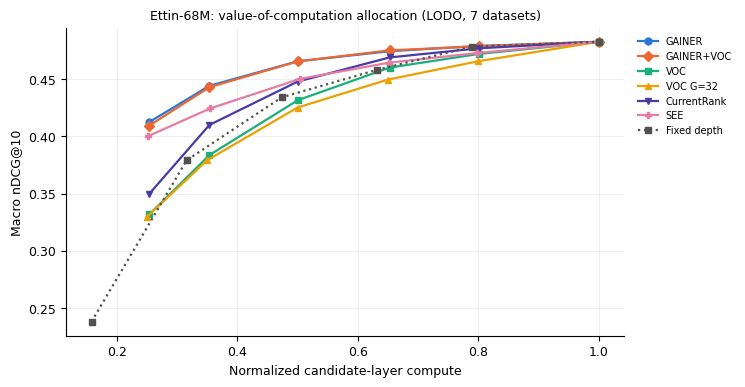

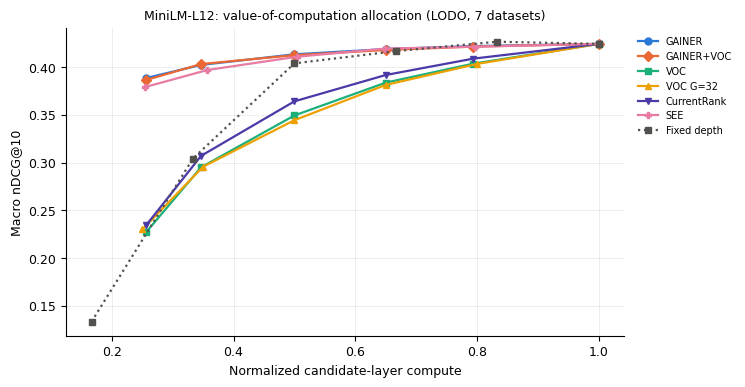

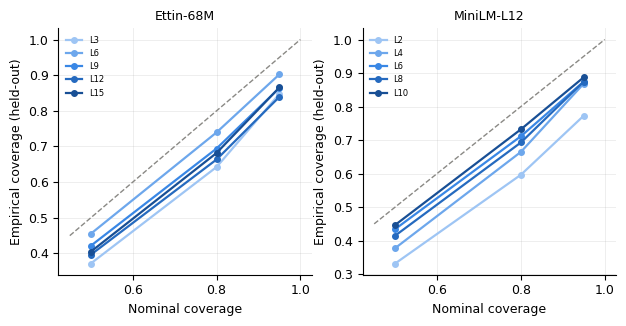

method,GAINER G=32,VOC G=32
dataset,,
arguana,-0.008,-0.025
fiqa,0.059,-0.082
nfcorpus,0.165,0.039
scidocs,-0.064,0.052
scifact,0.044,-0.097
trec-covid,-0.099,-0.133
webis-touche2020,-0.160,0.177


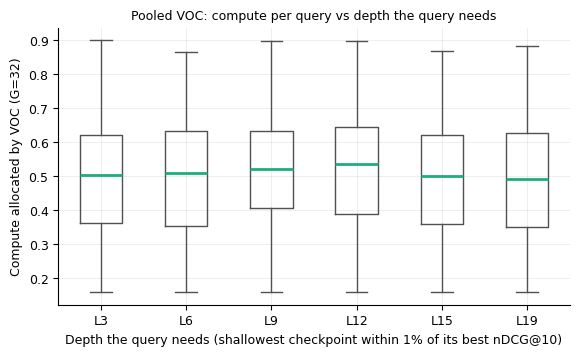

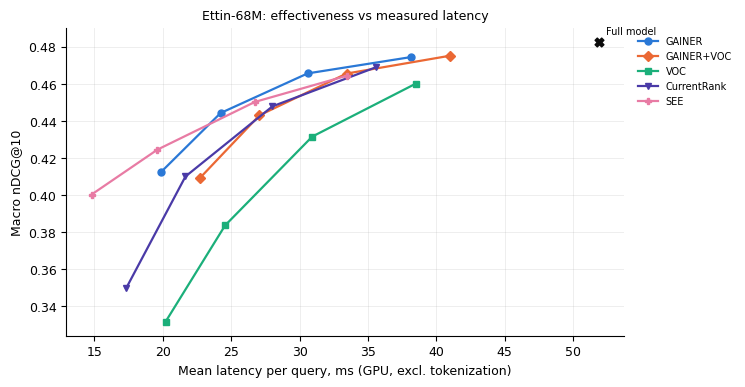

In [ ]:
def main_table(bb):
    L = BACKBONES[bb]["checkpoints"][-1]
    cols = [("CurrentRank", dict(method="CurrentRank", budget=P)), ("SEE", dict(method="SEE", budget=P)),
            ("GAINER", dict(method="GAINER", budget=P)), (f"GAINER G={GM}", dict(method="GAINER", budget=P, pool=GM)),
            ("VOC (label-free)", dict(method="VOC", budget=P)), (f"VOC G={GM}", dict(method="VOC", budget=P, pool=GM)),
            ("GAINER+VOC", dict(method="GAINER+VOC", budget=P)), (f"Full L{L}", dict(method=f"Fixed_L{L}"))]
    rows = []
    for name in DATASETS + ["Macro", "Compute"]:
        row = {"Dataset": name}
        for lab, spec in cols:
            pq = per_query(bb, **spec)
            if pq.empty:
                row[lab] = np.nan
            elif name == "Macro":
                row[lab] = macro(pq)
            elif name == "Compute":
                row[lab] = macro(pq, "cost")
            else:
                row[lab] = float(pq.loc[name, "ndcg"].mean()) if name in pq.index.get_level_values(0) else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

for bb in RUN_BACKBONES:
    t = main_table(bb)
    t.to_csv(TABLES / f"table_main_v3_1_{bb}.csv", index=False)
    t.to_latex(TABLES / f"table_main_v3_1_{bb}.tex", index=False, float_format="%.4f",
               caption=f"nDCG@10 at {int(P * 100)}% compute ({BACKBONES[bb]['label']}, LODO, mean of {len(SEEDS)} seeds).",
               label=f"tab:v31_{bb}")
    print(BACKBONES[bb]["label"]); display(t)

horizon = (res[(res.pool == 1) & res.method.isin(["VOC", "VOC (next block only)", "VOC (to final only)", "CurrentRank"])]
           .groupby(["backbone", "method", "budget", "dataset"]).ndcg.mean().groupby(["backbone", "method", "budget"]).mean()
           .unstack("budget").round(4))
horizon.to_csv(TABLES / "table_voc_horizon_ablation.csv")
display(horizon)

calib_t = calib.groupby(["backbone", "checkpoint"])[["coverage_50", "coverage_80", "coverage_95", "z_std",
                                                     "spearman_sigma_abs_error", "mean_sigma", "rmse"]].mean().round(3)
calib_t.to_csv(TABLES / "table_uncertainty_calibration.csv")
display(calib_t)

if not latency.empty:
    lat_t = latency.groupby("method").agg(mean_ms=("ms", "mean"), p50_ms=("ms", "median"),
                                          p95_ms=("ms", lambda x: np.percentile(x, 95)), queries=("qid", "nunique")).reset_index()
    def sim_ndcg(mname):
        meth, _, b = mname.partition("@")
        if meth == "Full (standard forward)":
            pq = per_query(MAIN_BACKBONE, f"Fixed_L{BACKBONES[MAIN_BACKBONE]['checkpoints'][-1]}")
        else:
            pq = per_query(MAIN_BACKBONE, meth, float(b))
        return macro(pq) if len(pq) else np.nan
    lat_t["macro_ndcg"] = lat_t.method.map(sim_ndcg)
    full_ms = float(lat_t.loc[lat_t.method == "Full (standard forward)", "mean_ms"].iloc[0])
    lat_t["speedup_vs_full"] = full_ms / lat_t.mean_ms
    lat_t = lat_t.sort_values("mean_ms")
    lat_t.to_csv(TABLES / "table_latency_v3_1.csv", index=False)
    display(lat_t)
    sim0 = res[(res.backbone == MAIN_BACKBONE) & (res.seed == LAT_SEED) & (res.pool == 1)]
    integ = []
    for mname, g in latency.groupby("method"):
        meth, _, b = mname.partition("@")
        if not b:
            continue
        s = sim0[(sim0.method == meth) & np.isclose(sim0.budget, float(b))].set_index("qid").ndcg
        j = g.set_index("qid").replay_ndcg.to_frame().join(s, how="inner")
        integ.append({"method": mname, "queries": len(j), "mean_abs_ndcg_diff": float((j.replay_ndcg - j.ndcg).abs().mean())})
    integ = pd.DataFrame(integ)
    integ.to_csv(TABLES / "latency_vs_simulation_integrity_v3_1.csv", index=False)
    print("Conditional execution vs simulation (should be ~0):"); display(integ)

COLORS = {"GAINER": "#2a78d6", "GAINER+VOC": "#eb6834", "VOC": "#1baf7a", f"VOC G={GM}": "#eda100",
          "CurrentRank": "#4a3aa7", "SEE": "#e87ba4", "Fixed depth": "#52514e"}
MARK = {"GAINER": "o", "GAINER+VOC": "D", "VOC": "s", f"VOC G={GM}": "^", "CurrentRank": "v", "SEE": "P"}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "lines.linewidth": 1.6, "savefig.dpi": 300, "savefig.bbox": "tight"})

def curve(bb, method, pool=1):
    sub = qavg[(qavg.backbone == bb) & (qavg.method == method) & (qavg.pool == pool)]
    d = sub.groupby(["budget_r", "dataset"]).agg(ndcg=("ndcg", "mean"), cost=("cost", "mean")).reset_index()
    return d.groupby("budget_r").agg(ndcg=("ndcg", "mean"), cost=("cost", "mean"), n=("dataset", "nunique")).reset_index().sort_values("cost")

for bb in RUN_BACKBONES:
    fig, ax = plt.subplots(figsize=(7.2, 4.0))
    for lab, method, pool in [("GAINER", "GAINER", 1), ("GAINER+VOC", "GAINER+VOC", 1), ("VOC", "VOC", 1),
                              (f"VOC G={GM}", "VOC", GM), ("CurrentRank", "CurrentRank", 1), ("SEE", "SEE", 1)]:
        c = curve(bb, method, pool); c = c[c.n == len(DATASETS)]
        if len(c):
            ax.plot(c.cost, c.ndcg, marker=MARK[lab], markersize=5, color=COLORS[lab], label=lab)
    layers = BACKBONES[bb]["checkpoints"]
    fx = [(l / layers[-1], macro(per_query(bb, f"Fixed_L{l}"))) for l in layers]
    ax.plot(*zip(*fx), marker="s", markersize=4, linestyle=":", color=COLORS["Fixed depth"], label="Fixed depth")
    ax.set_xlabel("Normalized candidate-layer compute"); ax.set_ylabel("Macro nDCG@10")
    ax.set_title(f"{BACKBONES[bb]['label']}: value-of-computation allocation (LODO, {len(DATASETS)} datasets)", fontsize=9)
    ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    fig.savefig(FIGS / f"fig_v31_pareto_{bb}.png"); fig.savefig(FIGS / f"fig_v31_pareto_{bb}.pdf"); plt.show()

# uncertainty calibration: empirical vs nominal coverage per checkpoint
fig, axes = plt.subplots(1, len(RUN_BACKBONES), figsize=(3.6 * len(RUN_BACKBONES), 3.2), squeeze=False)
for ax, bb in zip(axes[0], RUN_BACKBONES):
    ct = calib[calib.backbone == bb].groupby("checkpoint")[["coverage_50", "coverage_80", "coverage_95"]].mean()
    ramp = ["#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
    for i, (cp, row) in enumerate(ct.iterrows()):
        ax.plot([0.5, 0.8, 0.95], row.to_numpy(), marker="o", markersize=4, color=ramp[i % len(ramp)], label=f"L{cp}")
    ax.plot([0.45, 1.0], [0.45, 1.0], linestyle="--", color="#8a8985", linewidth=1)
    ax.set_xlabel("Nominal coverage"); ax.set_ylabel("Empirical coverage (held-out)")
    ax.set_title(BACKBONES[bb]["label"], fontsize=9)
    ax.legend(fontsize=6, frameon=False)
fig.savefig(FIGS / "fig_v31_uncertainty_calibration.png"); fig.savefig(FIGS / "fig_v31_uncertainty_calibration.pdf"); plt.show()

# does pooled VOC spend more compute on queries that need more depth (v3's pooled GAINER did not)?
need_rows = []
for bb in [MAIN_BACKBONE]:
    layers = BACKBONES[bb]["checkpoints"]
    fx = qavg[(qavg.backbone == bb) & qavg.method.str.startswith("Fixed_L")].copy()
    fx["layer"] = fx.method.str.replace("Fixed_L", "").astype(int)
    pv = fx.pivot_table(index=["dataset", "qid"], columns="layer", values="ndcg")[layers]
    best = pv.max(1); keep = best > 0
    need = pv[keep].ge(0.99 * best[keep], axis=0).idxmax(axis=1).rename("needed_layer").reset_index()
    for lab, method in [(f"VOC G={GM}", "VOC"), (f"GAINER G={GM}", "GAINER")]:
        a = per_query(bb, method, P, GM).reset_index().merge(need, on=["dataset", "qid"])
        for ds_, g in a.groupby("dataset"):
            need_rows.append({"method": lab, "dataset": ds_, "spearman_cost_vs_needed_depth": g.cost.corr(g.needed_layer, method="spearman")})
        if lab.startswith("VOC"):
            alloc_voc = a
alloc_t = pd.DataFrame(need_rows).pivot(index="dataset", columns="method", values="spearman_cost_vs_needed_depth").round(3)
alloc_t.to_csv(TABLES / "allocated_vs_needed_depth_v3_1.csv")
display(alloc_t)
fig, ax = plt.subplots(figsize=(6.6, 3.6))
layers = BACKBONES[MAIN_BACKBONE]["checkpoints"]
ax.boxplot([alloc_voc.loc[alloc_voc.needed_layer == l, "cost"].to_numpy() for l in layers],
           tick_labels=[f"L{l}" for l in layers], showfliers=False,
           medianprops=dict(color=COLORS["VOC"], linewidth=2), boxprops=dict(color="#52514e"),
           whiskerprops=dict(color="#52514e"), capprops=dict(color="#52514e"))
ax.set_xlabel("Depth the query needs (shallowest checkpoint within 1% of its best nDCG@10)")
ax.set_ylabel(f"Compute allocated by VOC (G={GM})")
ax.set_title("Pooled VOC: compute per query vs depth the query needs", fontsize=9)
fig.savefig(FIGS / "fig_v31_allocated_vs_needed.png"); fig.savefig(FIGS / "fig_v31_allocated_vs_needed.pdf"); plt.show()

if not latency.empty:
    fig, ax = plt.subplots(figsize=(7.2, 4.0))
    for fam in ["GAINER", "GAINER+VOC", "VOC", "CurrentRank", "SEE"]:
        sub = lat_t[lat_t.method.str.startswith(fam + "@")].sort_values("mean_ms")
        if len(sub):
            ax.plot(sub.mean_ms, sub.macro_ndcg, marker=MARK[fam], markersize=5, color=COLORS[fam], label=fam)
    r = lat_t[lat_t.method == "Full (standard forward)"]
    ax.scatter(r.mean_ms, r.macro_ndcg, marker="X", s=40, color="#0b0b0b", zorder=3)
    ax.annotate("Full model", (float(r.mean_ms.iloc[0]), float(r.macro_ndcg.iloc[0])), fontsize=7, xytext=(5, 5), textcoords="offset points")
    ax.set_xlabel(f"Mean latency per query, ms ({'GPU' if DEVICE == 'cuda' else 'CPU'}, excl. tokenization)")
    ax.set_ylabel("Macro nDCG@10")
    ax.set_title(f"{BACKBONES[MAIN_BACKBONE]['label']}: effectiveness vs measured latency", fontsize=9)
    ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    fig.savefig(FIGS / "fig_v31_pareto_latency.png"); fig.savefig(FIGS / "fig_v31_pareto_latency.pdf"); plt.show()

## 14. Decision gates and manifest

In [ ]:
h = primary.set_index("hypothesis")
lines = []
for hid, gate, yes, no in [
    ("H4", "G5  Label-free VOC beats the score cascade", "PASS: label-free allocation is a contribution",
     "FAIL: report VOC as a negative result"),
    ("H5", "G6  Calibrated values make cross-query pooling work", "PASS: pooling (query x candidate x layer) is a headline result",
     "FAIL: pooling stays a negative result"),
    ("H6", "G7  VOC terms improve the learned controller", "PASS: present GAINER+VOC as the main method",
     "FAIL: keep GAINER as the main method"),
]:
    r = h.loc[hid]
    lines.append(f"{gate} ({hid}): delta = {r['delta']:+.4f} [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}], "
                 f"Holm p = {r['p_holm']:.4f} -> {yes if r['supported'] else no}")
lf = label_free[(label_free.backbone == MAIN_BACKBONE) & np.isclose(label_free.budget, P)].iloc[0]
lines.append(f"Label-free VOC recovers {lf['VOC_share_of_GAINER_gain']:.0%} of GAINER's gain over Current Rank at {int(P*100)}% compute")
for bb in [b for b in RUN_BACKBONES if b != MAIN_BACKBONE]:
    for comp in ["VOC vs CurrentRank", "VOC pooled vs VOC", "GAINER+VOC vs GAINER"]:
        r = secondary[(secondary.backbone == bb) & (secondary.comparison == comp)].iloc[0]
        lines.append(f"Replication on {BACKBONES[bb]['label']}: {comp}: delta = {r['delta']:+.4f}, p = {r['p']:.4f}")
print("\n".join(lines))

manifest = {"finished_utc": datetime.now(timezone.utc).isoformat(),
            "prereg_sha256": json.loads(PREREG_PATH.read_text())["sha256"],
            "versions": {"torch": torch.__version__, "transformers": transformers.__version__,
                         "sentence_transformers": sentence_transformers.__version__},
            "device": torch.cuda.get_device_name(0) if DEVICE == "cuda" else platform.processor(),
            "gain_mode": GAIN_MODE, "gates": lines,
            "raw_files": len(list(RAW.glob("*.parquet")))}
(RESULTS / "run_manifest_v3_1.json").write_text(json.dumps(manifest, indent=2))
print("\nTables:", sorted(p.name for p in TABLES.iterdir()))
print("Figures:", sorted(p.name for p in FIGS.iterdir()))

G5  Label-free VOC beats the score cascade (H4): delta = -0.0163 [-0.0197, -0.0130], Holm p = 0.0000 -> FAIL: report VOC as a negative result
G6  Calibrated values make cross-query pooling work (H5): delta = -0.0063 [-0.0117, -0.0012], Holm p = 0.0343 -> FAIL: pooling stays a negative result
G7  VOC terms improve the learned controller (H6): delta = -0.0001 [-0.0021, +0.0018], Holm p = 0.9351 -> FAIL: keep GAINER as the main method
Label-free VOC recovers -92% of GAINER's gain over Current Rank at 50% compute
Replication on MiniLM-L12: VOC vs CurrentRank: delta = -0.0148, p = 0.0000
Replication on MiniLM-L12: VOC pooled vs VOC: delta = -0.0050, p = 0.0486
Replication on MiniLM-L12: GAINER+VOC vs GAINER: delta = -0.0009, p = 0.3096

Tables: ['allocated_vs_needed_depth_v3_1.csv', 'label_free_ratio.csv', 'latency_vs_simulation_integrity_v3_1.csv', 'leak_test_ettin68m.csv', 'leak_test_minilm12.csv', 'primary_hypotheses_v3_1.csv', 'reproduction_vs_v3.csv', 'secondary_tests_v3_1.csv', 'table